In [23]:
import sys
print(sys.executable)

c:\Users\karih\anaconda3\envs\papagei_env\python.exe


In [24]:
%pip install dotmap
%pip install vitaldb 
%pip install pyPPG==1.0.41
%pip install openpyxl
%pip install torch_ecg
%pip install "matplotlib-inline==0.1.6"

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedWriter name=3>
  return process_handler(cmd, _system_body)
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedReader name=5>
  return process_handler(cmd, _system_body)
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  return process_handler(cmd, _system_body)


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.


^C
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.
c:\Users\karih\anaconda3\envs\papagei_env\lib\threading.py:957: ResourceWarning: unclosed file <_io.BufferedWriter name=3>
  del self._target, self._args, self._kwargs
c:\Users\karih\anaconda3\envs\papagei_env\lib\threading.py:957: ResourceWarning: unclosed file <_io.BufferedReader name=5>
  del self._target, self._args, self._kwargs
c:\Users\karih\anaconda3\envs\papagei_env\lib\threading.py:957: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  del self._target, self._args, self._kwargs


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedWriter name=7>
  return process_handler(cmd, _system_body)
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedReader name=8>
  return process_handler(cmd, _system_body)
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\utils\_process_win32.py:124: ResourceWarning: unclosed file <_io.BufferedReader name=9>
  return process_handler(cmd, _system_body)


You should consider upgrading via the 'c:\Users\karih\anaconda3\envs\papagei_env\python.exe -m pip install --upgrade pip' command.


In [ ]:
import pandas as pd 
import numpy as np
import os 
import sys
import joblib
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm 
from linearprobing.utils import resample_batch_signal, load_model_without_module_prefix, get_data_for_ml
from preprocessing.ppg import preprocess_one_ppg_signal
from segmentations import waveform_to_segments, save_segments_to_directory
from sklearn.model_selection import train_test_split
from torch_ecg._preprocessors import Normalize
from models.resnet import ResNet1D, ResNet1DMoE
from linearprobing.feature_extraction_papagei import save_embeddings
from linearprobing.extracted_feature_combine import segment_avg_to_dict
from linearprobing.regression import regression_model

c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\torchvision\transforms\_functional_pil.py:242: DeprecationWarning: BILINEAR is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.BILINEAR instead.
  interpolation: int = Image.BILINEAR,
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\torchvision\transforms\_functional_pil.py:288: DeprecationWarning: NEAREST is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.NEAREST or Dither.NONE instead.
  interpolation: int = Image.NEAREST,
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\torchvision\transforms\_functional_pil.py:304: DeprecationWarning: NEAREST is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.NEAREST or Dither.NONE instead.
  interpolation: int = Image.NEAREST,
c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\torchvision\transforms\_functional_pil.py:321: DeprecationWarning: BICUBIC is deprecated and will be removed 

## 1. Data

- **(a)**: Download the PPG-BP data from [PPG-BP Database](https://figshare.com/articles/dataset/PPG-BP_Database_zip/5459299) to a directory.
  - Add the download path to `download_dir`.
- **(b)**: Use the download path for further pre-processing.
- **(c)**: Use pre-defined user splits for later linear evaluation


#### 1. (a)

In [ ]:
download_dir = "C:/UCD/papagei-foundation-model/data_PPG"

In [ ]:
df = pd.read_excel(f"{download_dir}/Data File/PPG-BP dataset.xlsx", header=1)

In [ ]:
#visualising data spreadsheet
print("Rows and columns:", df.shape)
print("Unique participants:", df["subject_ID"].nunique())
display(df.head())

Rows and columns: (219, 14)
Unique participants: 219


,Num.,subject_ID,Sex(M/F),Age(year),Height(cm),Weight(kg),Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m),BMI(kg/m^2),Hypertension,Diabetes,cerebral infarction,cerebrovascular disease
0,1,2,Female,45,152,63,161,89,97,27.268006,Stage 2 hypertension,NaN,NaN,NaN
1,2,3,Female,50,157,50,160,93,76,20.284799,Stage 2 hypertension,NaN,NaN,NaN
2,3,6,Female,47,150,47,101,71,79,20.888889,Normal,NaN,NaN,NaN
3,4,8,Male,45,172,65,136,93,87,21.971336,Prehypertension,NaN,NaN,NaN
4,5,9,Female,46,155,65,123,73,73,27.055151,Prehypertension,NaN,NaN,NaN


Signal shape: (2100,)
Duration: 2.1 seconds


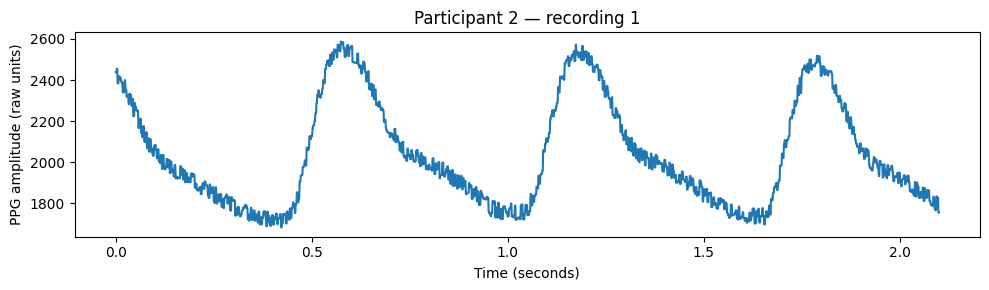

In [ ]:
#visualising PPG waveform
signal_path = (
    f"{download_dir}/Data File/0_subject/2_1.txt"
)

raw_signal = pd.read_csv(
    signal_path, sep="\t", header=None
).values.squeeze()

# The original notebook removes the last entry.
signal = raw_signal[:-1]

fs = 1000  # samples per second
time = np.arange(len(signal)) / fs

print("Signal shape:", signal.shape)
print("Duration:", len(signal) / fs, "seconds")

plt.figure(figsize=(10, 3))
plt.plot(time, signal)
plt.xlabel("Time (seconds)")
plt.ylabel("PPG amplitude (raw units)")
plt.title("Participant 2 — recording 1")
plt.tight_layout()
plt.show()

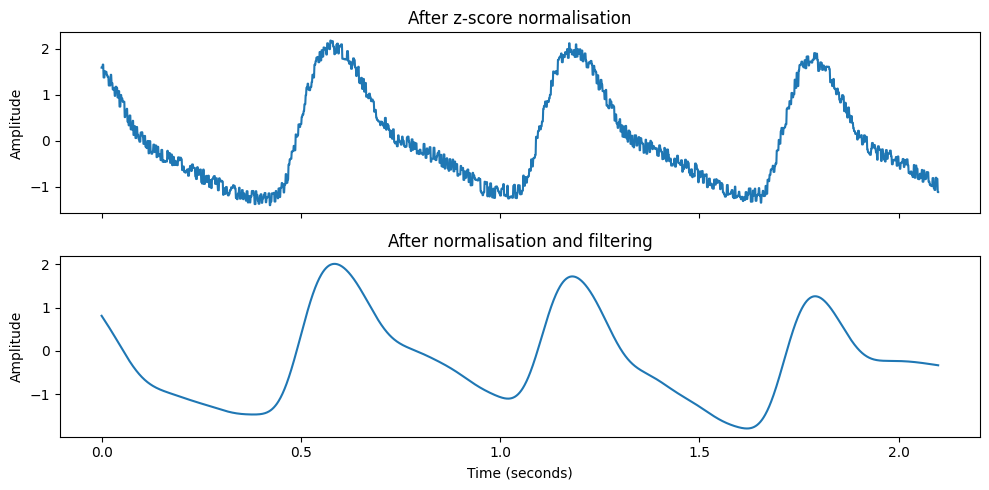

In [ ]:
norm = Normalize(method="z-score")

normalized_signal, _ = norm.apply(signal.copy(), fs=fs)

filtered_signal, _, _, _ = preprocess_one_ppg_signal(
    waveform=normalized_signal,
    frequency=fs
)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(time, normalized_signal)
axes[0].set_title("After z-score normalisation")
axes[0].set_ylabel("Amplitude")

axes[1].plot(time, filtered_signal)
axes[1].set_title("After normalisation and filtering")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [ ]:
import inspect

print(inspect.getsource(preprocess_one_ppg_signal))

def preprocess_one_ppg_signal(waveform,
                          frequency,
                          fL=0.5, 
                          fH=12, 
                          order=4, 
                          smoothing_windows={"ppg":50, "vpg":10, "apg":10, "jpg":10}):
    
    """
    Preprocessing a single PPG waveform using py PPG.
    https://pyppg.readthedocs.io/en/latest/Filters.html
    
    Args:
        waveform (numpy.array): PPG waveform for processing
        frequency (int): waveform frequency
        fL (float/int): high pass cut-off for chebyshev filter
        fH (float/int): low pass cut-off for chebyshev filter
        order (int): filter order
        smoothing_windows (dictionary): smoothing window sizes in milliseconds as dictionary
    
    Returns:
        ppg (numpy.array): filtered ppg signal
        ppg_d1 (numpy.array): first derivative of filtered ppg signal
        ppg_d2 (numpy.array): second derivative of filtered ppg signal
        ppg_d3 (numpy.array): t

In [ ]:
subjects = df.subject_ID.values
main_dir = f"{download_dir}/Data File/0_subject/"
ppg_dir = f"{download_dir}/Data File/ppg/"

if not os.path.exists(ppg_dir):
    os.mkdir(ppg_dir)
    
fs = 1000 
fs_target = 125

#### 1. (b)

In [ ]:
filenames = [f.split("_")[0] for f in os.listdir(main_dir)]

In [ ]:
#normalising by subtracting mean and and dividing by std
norm = Normalize(method='z-score')

#filtering, resampling and padding 
for f in tqdm(filenames):
    segments = []
    for s in range(1, 4):
        print(f"Processing: {f}_{s}")
        signal = pd.read_csv(f"{main_dir}{f}_{str(s)}.txt", sep='\t', header=None)
        signal = signal.values.squeeze()[:-1]
        signal, _ = norm.apply(signal, fs=fs)
        signal, _, _, _ = preprocess_one_ppg_signal(waveform=signal,
                                                frequency=fs)
        signal = resample_batch_signal(signal, fs_original=fs, fs_target=fs_target, axis=0)
        
        padding_needed = 1250 - len(signal)
        pad_left = padding_needed // 2
        pad_right = padding_needed - pad_left
        
        signal = np.pad(signal, pad_width=(pad_left, pad_right))
        segments.append(signal)
    segments = np.vstack(segments)
    child_dir = f.zfill(4)
    save_segments_to_directory(save_dir=ppg_dir,
                              dir_name=child_dir,
                              segments=segments)

#### 1. (c)

In [ ]:
df = df.rename(columns={"Sex(M/F)": "sex",
                   "Age(year)": "age",
                   "Systolic Blood Pressure(mmHg)": "sysbp",
                   "Diastolic Blood Pressure(mmHg)": "diasbp",
                   "Heart Rate(b/m)": "hr",
                   "BMI(kg/m^2)": "bmi"})
df = df.fillna(0)

In [ ]:
# These randomly selected subject splits used in our work.
# We hardcode them because we cannot share it as a "data source".

train_ids = [  2,   6,   8,  10,  12,  15,  16,  17,  18,  19,  22,  23,  26,
        31,  32,  34,  35,  38,  40,  45,  48,  50,  53,  55,  56,  58,
        60,  61,  63,  65,  66,  83,  85,  87,  89,  92,  93,  97,  98,
        99, 100, 104, 105, 106, 107, 112, 113, 114, 116, 120, 122, 126,
       128, 131, 134, 135, 137, 138, 139, 140, 141, 146, 148, 149, 152,
       153, 154, 158, 160, 162, 164, 165, 167, 169, 170, 175, 176, 179,
       183, 184, 186, 188, 189, 190, 191, 193, 196, 197, 199, 205, 206,
       207, 209, 210, 212, 216, 217, 218, 223, 226, 227, 230, 231, 233,
       234, 240, 242, 243, 244, 246, 247, 248, 256, 257, 404, 407, 409,
       412, 414, 415, 416, 417, 419]

test_ids = [14,  21,  25,  51,  52,  62,  67,  86,  90,  96, 103, 108, 110,
       119, 123, 124, 130, 142, 144, 157, 172, 173, 174, 180, 182, 185,
       192, 195, 200, 201, 211, 214, 219, 221, 228, 239, 250, 403, 405,
       406, 410]

val_ids = [3,  11,  24,  27,  29,  30,  41,  43,  47,  64,  88,  91,  95,
       115, 125, 127, 136, 145, 155, 156, 161, 163, 166, 178, 198, 203,
       208, 213, 215, 222, 229, 232, 235, 237, 241, 245, 252, 254, 259,
       411, 418]

df_train = df[df.subject_ID.isin(train_ids)]
df_val = df[df.subject_ID.isin(val_ids)]
df_test = df[df.subject_ID.isin(test_ids)]

df_train.to_csv(f"{download_dir}/Data File/train.csv", index=False)
df_val.to_csv(f"{download_dir}/Data File/val.csv", index=False)
df_test.to_csv(f"{download_dir}/Data File/test.csv", index=False)

In [ ]:
train = set(df_train["subject_ID"])
val = set(df_val["subject_ID"])
test = set(df_test["subject_ID"])

print("Participants:")
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

print("\nOverlapping participants:")
print("Train / validation:", len(train & val))
print("Train / test:", len(train & test))
print("Validation / test:", len(val & test))

assigned = train | val | test
all_participants = set(df["subject_ID"])

print("\nParticipants not assigned:", sorted(all_participants - assigned))

Participants:
Train: 123
Validation: 41
Test: 41

Overlapping participants:
Train / validation: 0
Train / test: 0
Validation / test: 0

Participants not assigned: [9, 13, 54, 57, 84, 111, 150, 151, 171, 220, 224, 251, 253, 413]


The supplied participant lists contain 123 training, 41 validation and 41 test participants, with no overlap. Fourteen of the 219 participants in the metadata are not included in these lists. The reason for their exclusion has not yet been established.

## 2. Extracting Features

In this section, we describe how to load the *PaPaGei* model and extract embeddings.
- **(a)**: Loading a model and extract embeddings from a single signal. This code will be most relevant to customize for your own problems.
- **(b)**: Function to extract features from all ppg segments (batched).
- **(c)**: Extracting *PaPaGei-S* features for PPG-BP.
- **(d)**: Extracting *PaPaGei-S sVRI only* features for PPG-BP.
- **(e)**: Extracting *PaPaGei-P* features for PPG-BP.

In [ ]:
batch_size = 256
device = "cpu"
case_name = "subject_ID"
ppg_dir = f"{download_dir}/Data File/ppg/"

df_train = pd.read_csv(f"{download_dir}/Data File/train.csv")
df_val = pd.read_csv(f"{download_dir}/Data File/val.csv")
df_test = pd.read_csv(f"{download_dir}/Data File/test.csv")

df_train.loc[:, case_name] = df_train[case_name].apply(lambda x:str(x).zfill(4))
df_val.loc[:, case_name] = df_val[case_name].apply(lambda x:str(x).zfill(4))
df_test.loc[:, case_name] = df_test[case_name].apply(lambda x:str(x).zfill(4))

dict_df = {'train': df_train, 'val': df_val, 'test': df_test}

#### 2. (a) Code to load model and extract embeddings for one signal

**Extend this code to extract features for your own datasets**

In [ ]:
model_config = {'base_filters': 32,
            'kernel_size': 3,
            'stride': 2,
            'groups': 1,
            'n_block': 18,
            'n_classes': 512,
            'n_experts': 3
            }

model = ResNet1DMoE(in_channels=1, 
            base_filters=model_config['base_filters'], 
            kernel_size=model_config['kernel_size'],
            stride=model_config['stride'],
            groups=model_config['groups'],
            n_block=model_config['n_block'],
            n_classes=model_config['n_classes'],
            n_experts=model_config['n_experts'])

model_path = "weights/papagei_s.pt"
model = load_model_without_module_prefix(model, model_path)
model.to(device)

ResNet1DMoE(
  (first_block_conv): MyConv1dPadSame(
    (conv): Conv1d(1, 32, kernel_size=(3,), stride=(1,))
  )
  (first_block_bn): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (first_block_relu): ReLU()
  (basicblock_list): ModuleList(
    (0): BasicBlock(
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU()
      (do1): Dropout(p=0.5, inplace=False)
      (conv1): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu2): ReLU()
      (do2): Dropout(p=0.5, inplace=False)
      (conv2): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (max_pool): MyMaxPool1dPadSame(
        (max_pool): MaxPool1d(kernel_size=1, stride=1, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): BasicBlock(
      (bn1): Bat

In [ ]:
# load a signal
# note that that signal is already resampled and normalized
signal = joblib.load(os.path.join(ppg_dir, '0002', '0.p'))
signal = torch.Tensor(signal)
signal = signal[None, :].unsqueeze(dim=0)
print(f"PPG dimensions before inference : {signal.shape}")

model.eval()
with torch.inference_mode():
    signal = signal.to(device)
    outputs = model(signal)
    embeddings = outputs[0].cpu().detach().numpy()
print(f"Embedding dimensions : {embeddings.shape}")

PPG dimensions before inference : torch.Size([1, 1, 1250])
Embedding dimensions : (1, 512)


#### 2. (b) Extracting features for all ppg data and saving them for downstream use

In [ ]:
def extract_features_and_save(model, ppg_dir, batch_size, device, output_idx, resample, normalize, fs, fs_target, content):
    """
    Function to extract features and save them
    """
    for split in ['train', 'val', 'test']:
        # Choose one split at a time
        df = dict_df[split]
        save_dir = f"{download_dir}/features"

        # Creating require directory structure and names
        if not os.path.exists(f"{save_dir}"):
            os.mkdir(f"{save_dir}")
        
        model_name = model_path.split("/")[-1].split(".pt")[0]
        if not os.path.exists(f"{save_dir}/{model_name}"):
            os.mkdir(f"{save_dir}/{model_name}")
        split_dir = f"{save_dir}/{model_name}/{split}/"
        
        child_dirs = np.unique(df[case_name].values)

        # Function that extracts and saves embeddings
        save_embeddings(path=ppg_dir,
                        child_dirs=child_dirs, 
                        save_dir=split_dir, 
                        model=model, 
                        batch_size=batch_size, 
                        device=device, 
                        output_idx=output_idx,
                        resample=resample, 
                        normalize=normalize, 
                        fs=fs, 
                        fs_target=fs_target)
        
        # Compile the extracted embeddings at the patient or segment level adn save it               
        dict_feat = segment_avg_to_dict(split_dir, content)
        joblib.dump(dict_feat, f"{save_dir}/{model_name}/dict_{split}_{content}.p")

#### 2. (c) Extraction: PaPaGei-S

In [ ]:
model_config = {'base_filters': 32,
            'kernel_size': 3,
            'stride': 2,
            'groups': 1,
            'n_block': 18,
            'n_classes': 512,
            'n_experts': 3
            }

model = ResNet1DMoE(in_channels=1, 
            base_filters=model_config['base_filters'], 
            kernel_size=model_config['kernel_size'],
            stride=model_config['stride'],
            groups=model_config['groups'],
            n_block=model_config['n_block'],
            n_classes=model_config['n_classes'],
            n_experts=model_config['n_experts'])

model_path = "weights/papagei_s.pt"
model = load_model_without_module_prefix(model, model_path)
model.to(device)

ResNet1DMoE(
  (first_block_conv): MyConv1dPadSame(
    (conv): Conv1d(1, 32, kernel_size=(3,), stride=(1,))
  )
  (first_block_bn): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (first_block_relu): ReLU()
  (basicblock_list): ModuleList(
    (0): BasicBlock(
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU()
      (do1): Dropout(p=0.5, inplace=False)
      (conv1): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu2): ReLU()
      (do2): Dropout(p=0.5, inplace=False)
      (conv2): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (max_pool): MyMaxPool1dPadSame(
        (max_pool): MaxPool1d(kernel_size=1, stride=1, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): BasicBlock(
      (bn1): Bat

In [ ]:
extract_features_and_save(model=model,
                         ppg_dir=ppg_dir,
                         batch_size=batch_size,
                         device=device,
                         output_idx=0,
                         resample=False,
                         normalize=False,
                         fs=125,
                         fs_target=125,
                         content="patient"
                         )

In [ ]:
#confirming correct test/train/valid data split
feature_dir = os.path.join(download_dir, "features", "papagei_s")

for split in ["train", "val", "test"]:
    embeddings = joblib.load(
        os.path.join(feature_dir, f"dict_{split}_patient.p")
    )

    first_id = next(iter(embeddings))

    print(
        f"{split}: {len(embeddings)} participants | "
        f"embedding shape: {np.asarray(embeddings[first_id]).shape}"
    )

train: 123 participants | embedding shape: (512,)
val: 41 participants | embedding shape: (512,)
test: 41 participants | embedding shape: (512,)


#### 2. (d) Extraction: PaPaGei-S sVRI only

In [ ]:
model_config = {'base_filters': 32,
        'kernel_size': 3,
        'stride': 2,
        'groups': 1,
        'n_block': 18,
        'n_classes': 512,
        }

model = ResNet1D(in_channels=1, 
            base_filters=model_config['base_filters'], 
            kernel_size=model_config['kernel_size'],
            stride=model_config['stride'],
            groups=model_config['groups'],
            n_block=model_config['n_block'],
            n_classes=model_config['n_classes'],
            use_mt_regression=False,
            use_projection=False)

model_path = "weights/papagei_s_svri.pt"
model = load_model_without_module_prefix(model, model_path)
model.to(device)

ResNet1D(
  (first_block_conv): MyConv1dPadSame(
    (conv): Conv1d(1, 32, kernel_size=(3,), stride=(1,))
  )
  (first_block_bn): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (first_block_relu): ReLU()
  (basicblock_list): ModuleList(
    (0): BasicBlock(
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU()
      (do1): Dropout(p=0.5, inplace=False)
      (conv1): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu2): ReLU()
      (do2): Dropout(p=0.5, inplace=False)
      (conv2): MyConv1dPadSame(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (max_pool): MyMaxPool1dPadSame(
        (max_pool): MaxPool1d(kernel_size=1, stride=1, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): BasicBlock(
      (bn1): BatchN

In [ ]:
extract_features_and_save(model=model,
                         ppg_dir=ppg_dir,
                         batch_size=batch_size,
                         device=device,
                         output_idx=0,
                         resample=False,
                         normalize=False,
                         fs=125,
                         fs_target=125,
                         content="patient"
                         )

#### 2. (e) Extraction: PaPaGei-P

In [ ]:
model_config = {'base_filters': 32,
                'kernel_size': 3,
                'stride': 2,
                'groups': 1,
                'n_block': 18,
                'n_classes': 512,
                }

model = ResNet1D(in_channels=1, 
            base_filters=model_config['base_filters'], 
            kernel_size=model_config['kernel_size'],
            stride=model_config['stride'],
            groups=model_config['groups'],
            n_block=model_config['n_block'],
            n_classes=model_config['n_classes'])

model_path = "weights/papagei_p.pt"
model = load_model_without_module_prefix(model, model_path)
model.to(device)

In [ ]:
extract_features_and_save(model=model,
                         ppg_dir=ppg_dir,
                         batch_size=batch_size,
                         device=device,
                         output_idx=0,
                         resample=False,
                         normalize=False,
                         fs=125,
                         fs_target=125,
                         content="patient"
                         )

## 3. Linear Evaluation

In this section, we use the extracted embeddings to predict diastolic BP, systolic BP, and Average HR.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [ ]:
save_dir = f"{download_dir}/features/"
df_train = pd.read_csv(f"{download_dir}/Data File/train.csv")
df_val = pd.read_csv(f"{download_dir}/Data File/val.csv")
df_test = pd.read_csv(f"{download_dir}/Data File/test.csv")

df_train.loc[:, case_name] = df_train[case_name].apply(lambda x:str(x).zfill(4))
df_val.loc[:, case_name] = df_val[case_name].apply(lambda x:str(x).zfill(4))
df_test.loc[:, case_name] = df_test[case_name].apply(lambda x:str(x).zfill(4))
                                                                          
case_name = "subject_ID"

NameError: name 'case_name' is not defined

In [ ]:
#I am combining val and test set here!!!
def regression(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [ ]:
results_papagei_s = regression(save_dir=save_dir,
                                    model_name='papagei_s',
                                    content="patient",
                                    df_train=df_train,
                                    df_val=df_val,
                                    df_test=df_test,
                                    case_name=case_name,
                                    label="hr")

results_papagei_svri = regression(save_dir=save_dir,
                                    model_name='papagei_s_svri',
                                    content="patient",
                                    df_train=df_train,
                                    df_val=df_val,
                                    df_test=df_test,
                                    case_name=case_name,
                                    label="hr")

results_papagei_p = regression(save_dir=save_dir,
                                    model_name='papagei_p',
                                    content="patient",
                                    df_train=df_train,
                                    df_val=df_val,
                                    df_test=df_test,
                                    case_name=case_name,
                                    label="hr")

Fitting 4 folds for each of 15 candidates, totalling 60 fits
Fitting 4 folds for each of 15 candidates, totalling 60 fits
Fitting 4 folds for each of 15 candidates, totalling 60 fits


In [ ]:
print(f"PaPaGei-S HR MAE: {results_papagei_s['mae']}")
print(f"PaPaGei-S sVRI  HR MAE: {results_papagei_svri['mae']}")
print(f"PaPaGei-P HR MAE: {results_papagei_p['mae']}")

PaPaGei-S HR MAE: 4.535240545505431
PaPaGei-S sVRI  HR MAE: 4.822339825513886
PaPaGei-P HR MAE: 4.5845450889773485


In [ ]:
import importlib
import results_utils

importlib.reload(results_utils)
from results_utils import record_result

print("Function loaded successfully")

Function loaded successfully


In [ ]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
results_csv = results_dir / "evaluation_log.csv"

rows = []

for (model_name, target), result in all_results.items():
    run_id = f"{batch_id}_{model_name}_{target}"

    # Preserve the complete result alongside its CSV entry.
    joblib.dump(result, results_dir / f"{run_id}.joblib")

    row = record_result(
        result=result,
        model_name=model_name,
        target=target,
        n_train=len(df_train),
        procedure="released_notebook_val_plus_test",
        csv_path=results_csv,
        run_id=run_id
    )
    rows.append(row)

display(pd.DataFrame(rows).round(4))

NameError: name 'Path' is not defined

In [ ]:
paper = pd.read_csv("results/paper_reference_results.csv")
runs = pd.read_csv("results/evaluation_log.csv")

comparison = runs.merge(
    paper[paper["metric"] == "mae"],
    on=["model", "target"],
    how="left",
    validate="many_to_one"
)

comparison["mae_difference"] = (
    comparison["mae"] - comparison["paper_score"]
)

comparison.to_csv("results/paper_comparison.csv", index=False)

display(comparison[[
    "model", "target", "mae", "paper_score",
    "mae_difference", "ci_lower", "ci_upper",
    "paper_ci_lower", "paper_ci_upper"
]].round(4))

,model,target,mae,paper_score,mae_difference,ci_lower,ci_upper,paper_ci_lower,paper_ci_upper
0,papagei_s,diasbp,8.9095,8.71,0.1995,7.5022,10.3151,7.18,10.01
1,papagei_s,sysbp,14.2535,14.39,-0.1365,11.8955,16.6615,12.53,16.45
2,papagei_s,hr,4.5352,4.00,0.5352,3.7855,5.3325,3.34,4.67
3,papagei_s_svri,diasbp,9.2452,9.12,0.1252,7.8628,10.6418,NaN,NaN
4,papagei_s_svri,sysbp,14.2187,15.03,-0.8113,11.9213,16.6278,NaN,NaN
5,papagei_s_svri,hr,4.8223,4.00,0.8223,3.9754,5.6198,NaN,NaN
6,papagei_p,diasbp,8.8820,8.88,0.0020,7.5605,10.3076,7.33,10.76
7,papagei_p,sysbp,14.3074,13.60,0.7074,11.8816,16.5601,10.65,16.51
8,papagei_p,hr,4.5845,3.47,1.1145,3.7451,5.4683,2.74,4.32


Under the released example notebook’s evaluation procedure, the reproduced MAEs differ from the published values. Diastolic BP discrepancies range from 0.002 to 0.200 mmHg. All three heart-rate MAEs are higher than published, and the ordering of model variants differs for the blood-pressure tasks. These comparisons remain provisional until the paper and code evaluation procedures have been checked.

***INSPECTING WHY RESULTS DIFFER***

In [ ]:
import inspect
print(inspect.getsource(regression_model))

def regression_model(estimator, param_grid, X_train, y_train, X_test, y_test):

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    grid_search = GridSearchCV(estimator=estimator, 
                        param_grid=param_grid, 
                        cv=4, 
                        scoring='neg_mean_squared_error', 
                        verbose=2, 
                        n_jobs=-1)

    grid_search.fit(X_train, y_train)
    y_pred = grid_search.predict(X_test)

    lower_bound_ci_mae, upper_bound_ci_mae, _ = bootstrap_metric_confidence_interval(y_test=y_test,
                                                                                        y_pred=y_pred,
                                                                                        metric_func=mean_absolute_error)

    lower_bound_ci_r2, upper_bound_ci_r2, _ = bootstrap_metric_confidence_interval(y_test=y_test,
                                         

In [ ]:
import inspect

print(inspect.getsource(save_embeddings))
print(inspect.getsource(segment_avg_to_dict))

def save_embeddings(path, child_dirs, save_dir, model, batch_size, device, output_idx, resample=False, normalize=True, fs=None, fs_target=None, is_mt_regress=False):
    dict_embeddings = {}

    if not os.path.exists(save_dir):
        os.mkdir(save_dir)
        print(f"[INFO] Creating directory: {save_dir}")
    else:
        print(f"[INFO] {save_dir} already exists")

    for i in tqdm(range(len(child_dirs))):
        case = str(child_dirs[i])
        embeddings = compute_signal_embeddings(model=model,
                                            path=path,
                                            case=case,
                                            batch_size=batch_size,
                                            device=device,
                                            output_idx=output_idx,
                                            resample=resample,
                                            normalize=normalize,
                                            fs=fs,
       

Purpose: To check what happens to the model’s features after they are extracted—how they are saved and how the three recordings from one person are combined.

Finding: The code saves features separately for each participant, then averages the features from their recordings into one feature vector per person. It averages the extracted features, not the raw PPG signals.

In [ ]:
compute_fn = save_embeddings.__globals__["compute_signal_embeddings"]
print(inspect.getsource(compute_fn))

def compute_signal_embeddings(model, path, case, batch_size, device, output_idx, resample=False, normalize=True, fs=None, fs_target=None, is_mt_regress=False):
    segments = os.listdir(os.path.join(path, case))
    embeddings = []
    model.eval()
    norm = Normalize(method='z-score')

    with torch.inference_mode():
        for i in range(0, len(segments), batch_size):
            batch_signal = batch_load_signals(path, case, segments[i:i+batch_size])
            if normalize:
                batch_signal = np.vstack([norm.apply(s, fs)[0] for s in batch_signal])
            if resample:
                batch_signal = resample_batch_signal(batch_signal, fs, fs_target)
            batch_signal = torch.Tensor(batch_signal).unsqueeze(dim=1).to(device)
            outputs = model(batch_signal)
            embeddings.append(outputs[output_idx].cpu().detach().numpy())

    embeddings = np.vstack(embeddings)

    return embeddings



Purpose: To check how the processed PPG recordings are fed through PaPaGei to produce features.

Finding: The model runs in evaluation mode,the signals are not normalised or resampled again. The function extracts and combines the feature batches.

rules out repeated preprocessing and missing evaluation mode as the problem

In [ ]:
print("ResNet1DMoE forward:")
print(inspect.getsource(ResNet1DMoE.forward))

print("\nResNet1D forward:")
print(inspect.getsource(ResNet1D.forward))

ResNet1DMoE forward:
    def forward(self, x):
        out = x
        
        # First conv layer
        if self.verbose:
            print('input shape', out.shape)
        out = self.first_block_conv(out)
        if self.verbose:
            print('after first conv', out.shape)
        if self.use_bn:
            out = self.first_block_bn(out)
        out = self.first_block_relu(out)
        
        # Residual blocks
        for i_block in range(self.n_block):
            net = self.basicblock_list[i_block]
            if self.verbose:
                print('i_block: {0}, in_channels: {1}, out_channels: {2}, downsample: {3}'.format(i_block, net.in_channels, net.out_channels, net.downsample))
            out = net(out)
            if self.verbose:
                print(out.shape)

        # Final layers
        if self.use_bn:
            out = self.final_bn(out)
        out = self.final_relu(out)
        out = out.mean(-1)
        if self.verbose:
            print('final pooling'

Purpose: To check what each model returns, so we could understand what selecting outputs[0] actually keeps.

Finding: Both architectures return several outputs grouped together. Selecting [0] keeps the first output—the transformed features—for all recordings in the batch. It does not accidentally keep only the first recording.

->rules out extraction mistake

## Investigating differences from the published MAE

The released notebook produces MAEs that differ from the paper. The following checks investigate possible explanations by changing one aspect at a time.
The original results are retained as the reference.

### 1. Ridge alpha grid
The notebook searches alpha values [0.1, 1, 10, 100, 1000], whereas Appendix A lists [0.1, 1, 10, 100]. We will remove 1000 while keepingeverything else unchanged to measure the effect of this difference.


In [ ]:
results_dir = Path("results")
log = pd.read_csv(results_dir / "evaluation_log.csv")

original_rows = log[
    log["procedure"] == "released_notebook_val_plus_test"
].drop_duplicates(subset=["model", "target"], keep="last")

if len(original_rows) != 9:
    raise ValueError(
        f"Found {len(original_rows)} original combinations; expected 9."
    )

# Check all files exist before loading.
paths = {
    (row["model"], row["target"]):
        results_dir / f"{row['run_id']}.joblib"
    for _, row in original_rows.iterrows()
}

missing = [str(path) for path in paths.values() if not path.exists()]

if missing:
    raise FileNotFoundError(
        "Missing saved result files:\n" + "\n".join(missing)
    )

all_results = {
    key: joblib.load(path)
    for key, path in paths.items()
}

print("Original results restored:", len(all_results))

Original results restored: 9


In [ ]:
#I am combining val and test set here!!!
def regression(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [ ]:
from datetime import datetime, timezone

In [ ]:

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
results_csv = results_dir / "evaluation_log.csv"

batch_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

alpha_results = {}
rows = []

for model_name in ["papagei_s", "papagei_s_svri", "papagei_p"]:
    for target in ["diasbp", "sysbp", "hr"]:

        # Run regression using the edited alpha grid.
        result = regression(
            save_dir=save_dir,
            model_name=model_name,
            content="patient",
            df_train=df_train,
            df_val=df_val,
            df_test=df_test,
            case_name=case_name,
            label=target
        )

        alpha_results[(model_name, target)] = result
        run_id = f"{batch_id}_{model_name}_{target}"

        joblib.dump(result, results_dir / f"{run_id}.joblib")

        row = record_result(
            result=result,
            model_name=model_name,
            target=target,
            n_train=len(df_train),
            procedure="paper_alpha_grid_val_plus_test",
            csv_path=results_csv,
            run_id=run_id
        )
        rows.append(row)

display(pd.DataFrame(rows).round(4))

Fitting 4 folds for each of 12 candidates, totalling 48 fits

papagei_s — Diastolic BP
MAE: 8.9500 mmHg
95% CI: [7.4117, 10.3663] mmHg
Settings: {'alpha': 100.0, 'solver': 'auto'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 12 candidates, totalling 48 fits

papagei_s — Systolic BP
MAE: 14.3709 mmHg
95% CI: [12.4111, 16.7285] mmHg
Settings: {'alpha': 100.0, 'solver': 'auto'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 12 candidates, totalling 48 fits

papagei_s — Heart rate
MAE: 4.5352 beats/min
95% CI: [3.7668, 5.3837] beats/min
Settings: {'alpha': 100.0, 'solver': 'sparse_cg'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 12 candidates, totalling 48 fits

papagei_s_svri — Diastolic BP
MAE: 9.9687 mmHg
95% CI: [8.4784, 11.5943] mmHg
Settings: {'alph

,run_id,model,target,target_name,units,procedure,n_train,n_evaluation,mae,ci_lower,ci_upper,parameters
0,20261024T160614603340Z_papagei_s_diasbp,papagei_s,diasbp,Diastolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,8.9500,7.4117,10.3663,"{""alpha"": 100.0, ""solver"": ""auto""}"
1,20261024T160614603340Z_papagei_s_sysbp,papagei_s,sysbp,Systolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,14.3709,12.4111,16.7285,"{""alpha"": 100.0, ""solver"": ""auto""}"
2,20261024T160614603340Z_papagei_s_hr,papagei_s,hr,Heart rate,beats/min,paper_alpha_grid_val_plus_test,123,82,4.5352,3.7668,5.3837,"{""alpha"": 100.0, ""solver"": ""sparse_cg""}"
3,20261024T160614603340Z_papagei_s_svri_diasbp,papagei_s_svri,diasbp,Diastolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,9.9687,8.4784,11.5943,"{""alpha"": 100.0, ""solver"": ""auto""}"
4,20261024T160614603340Z_papagei_s_svri_sysbp,papagei_s_svri,sysbp,Systolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,14.4076,11.9831,16.8219,"{""alpha"": 100.0, ""solver"": ""sparse_cg""}"
5,20261024T160614603340Z_papagei_s_svri_hr,papagei_s_svri,hr,Heart rate,beats/min,paper_alpha_grid_val_plus_test,123,82,4.8223,4.0583,5.5961,"{""alpha"": 100.0, ""solver"": ""sparse_cg""}"
6,20261024T160614603340Z_papagei_p_diasbp,papagei_p,diasbp,Diastolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,9.3759,7.6940,11.2046,"{""alpha"": 100.0, ""solver"": ""auto""}"
7,20261024T160614603340Z_papagei_p_sysbp,papagei_p,sysbp,Systolic BP,mmHg,paper_alpha_grid_val_plus_test,123,82,17.9460,15.1400,20.8849,"{""alpha"": 100.0, ""solver"": ""auto""}"
8,20261024T160614603340Z_papagei_p_hr,papagei_p,hr,Heart rate,beats/min,paper_alpha_grid_val_plus_test,123,82,4.3266,3.5688,5.2859,"{""alpha"": 100.0, ""solver"": ""auto""}"


In [ ]:
alpha_comparison = pd.DataFrame([
    {
        "model": model,
        "target": target,
        "original_alpha": all_results[(model, target)]["parameters"]["alpha"],
        "new_alpha": result["parameters"]["alpha"],
        "original_mae": all_results[(model, target)]["mae"],
        "new_mae": result["mae"],
        "mae_change": (
            result["mae"] - all_results[(model, target)]["mae"]
        )
    }
    for (model, target), result in alpha_results.items()
])

alpha_comparison.to_csv(
    results_dir / "alpha_grid_comparison.csv",
    index=False
)

display(alpha_comparison.round(4))

,model,target,original_alpha,new_alpha,original_mae,new_mae,mae_change
0,papagei_s,diasbp,1000.0,100.0,8.9095,8.9500,0.0405
1,papagei_s,sysbp,1000.0,100.0,14.2535,14.3709,0.1173
2,papagei_s,hr,100.0,100.0,4.5352,4.5352,0.0000
3,papagei_s_svri,diasbp,1000.0,100.0,9.2452,9.9687,0.7234
4,papagei_s_svri,sysbp,1000.0,100.0,14.2187,14.4076,0.1888
5,papagei_s_svri,hr,100.0,100.0,4.8223,4.8223,0.0000
6,papagei_p,diasbp,1000.0,100.0,8.8820,9.3759,0.4939
7,papagei_p,sysbp,1000.0,100.0,14.3074,17.9460,3.6385
8,papagei_p,hr,1000.0,100.0,4.5845,4.3266,-0.2580


***Effect of the Ridge alpha grid***

Removing alpha=1000 changed seven of the nine MAEs. Six increased,
one decreased, and two remained unchanged. The largest change occurred for PaPaGei-P systolic BP: MAE increased
from 14.307 to 17.946 mmHg. PaPaGei-S systolic BP moved closer to
the published score, while other results moved further away.

Therefore, the alpha-grid difference affects the reproduced results
but does not consistently explain the discrepancies with the paper.
All other settings and the 82-person evaluation were held fixed.

### 2. Evaluation participants
The supplied splits contain 123 training, 41 validation and 41 test participants. The notebook combines validation and test for evaluation on 82 participants, whereas the paper describes separate splits. We will compare combined and separate evaluation scores. Which participants were used for the published scores remains unclear.

In [ ]:
from sklearn.metrics import mean_absolute_error

split_rows = []

for (model_name, target), result in all_results.items():

    # Recover the target ordering used by the original function.
    feature_dir = Path(download_dir) / "features" / model_name

    test_embeddings = joblib.load(
        feature_dir / "dict_test_patient.p"
    )
    val_embeddings = joblib.load(
        feature_dir / "dict_val_patient.p"
    )

    _, expected_test_y, _ = get_data_for_ml(
        df=df_test,
        dict_embeddings=test_embeddings,
        case_name=case_name,
        label=target
    )

    _, expected_val_y, _ = get_data_for_ml(
        df=df_val,
        dict_embeddings=val_embeddings,
        case_name=case_name,
        label=target
    )

    expected_test_y = np.asarray(expected_test_y).reshape(-1)
    expected_val_y = np.asarray(expected_val_y).reshape(-1)

    y_true = np.asarray(result["y_test"]).reshape(-1)
    y_pred = np.asarray(result["y_pred"]).reshape(-1)

    # Verify the saved results use test-then-validation ordering.
    expected_y = np.concatenate(
        (expected_test_y, expected_val_y)
    )
    np.testing.assert_allclose(y_true, expected_y)
    assert len(y_pred) == len(y_true)

    n_test = len(expected_test_y)

    test_mae = mean_absolute_error(
        y_true[:n_test], y_pred[:n_test]
    )
    val_mae = mean_absolute_error(
        y_true[n_test:], y_pred[n_test:]
    )
    combined_mae = mean_absolute_error(y_true, y_pred)

    split_rows.append({
        "model": model_name,
        "target": target,
        "alpha": result["parameters"]["alpha"],
        "n_test": n_test,
        "n_validation": len(expected_val_y),
        "combined_mae": combined_mae,
        "test_mae": test_mae,
        "validation_mae": val_mae,
        "test_minus_combined": test_mae - combined_mae
    })

split_comparison = pd.DataFrame(split_rows)

split_comparison.to_csv(
    results_dir / "evaluation_split_comparison.csv",
    index=False
)

display(split_comparison.round(4))

,model,target,alpha,n_test,n_validation,combined_mae,test_mae,validation_mae,test_minus_combined
0,papagei_s,diasbp,1000.0,41,41,8.9095,9.5171,8.3020,0.6076
1,papagei_s,sysbp,1000.0,41,41,14.2535,14.4042,14.1029,0.1507
2,papagei_s,hr,100.0,41,41,4.5352,4.5947,4.4757,0.0595
3,papagei_s_svri,diasbp,1000.0,41,41,9.2452,9.9074,8.5831,0.6621
4,papagei_s_svri,sysbp,1000.0,41,41,14.2187,14.7206,13.7169,0.5018
5,papagei_s_svri,hr,100.0,41,41,4.8223,4.9656,4.6790,0.1433
6,papagei_p,diasbp,1000.0,41,41,8.8820,9.5395,8.2246,0.6574
7,papagei_p,sysbp,1000.0,41,41,14.3074,14.7046,13.9102,0.3972
8,papagei_p,hr,1000.0,41,41,4.5845,4.2464,4.9227,-0.3382


***Effect of evaluation participants***

Using the same fitted models and predictions, test-only MAE was higher than combined validation/test MAE in eight of nine experiments.

PaPaGei-S systolic BP test-only MAE was 14.404 mmHg, close to the published 14.39 mmHg. However, test-only evaluation did not consistently bring the other results closer to the paper.

Evaluation-set composition therefore affects the reported scores, but this check does not establish which participants produced the published results. No models were refitted, and the original tuning was retained.



### 3. Feature scaling during cross-validation
The notebook fits StandardScaler on all training participants before four-fold cross-validation. We will instead fit scaling within each training fold using a pipeline, keeping other settings fixed, to assess whether this affects hyperparameter selection and MAE.

In [ ]:
bootstrap_metric_confidence_interval = (
    regression_model.__globals__["bootstrap_metric_confidence_interval"]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV


def regression_model_pipeline(
    estimator, param_grid, X_train, y_train, X_test, y_test
):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", estimator)
    ])

    pipeline_grid = {
        f"regressor__{key}": values
        for key, values in param_grid.items()
    }

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=pipeline_grid,
        cv=4,
        scoring="neg_mean_squared_error",
        verbose=2,
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)
    y_pred = grid_search.predict(X_test)

    lower_mae, upper_mae, _ = bootstrap_metric_confidence_interval(
        y_test=y_test,
        y_pred=y_pred,
        metric_func=mean_absolute_error
    )

    return {
        "parameters": {
            key.replace("regressor__", ""): value
            for key, value in grid_search.best_params_.items()
        },
        "mae": mean_absolute_error(y_test, y_pred),
        "lower_bound_mae": lower_mae,
        "upper_bound_mae": upper_mae,
        "y_test": np.asarray(y_test).tolist(),
        "y_pred": np.asarray(y_pred).tolist()
    }

In [ ]:
#I am combining val and test set here!!!
def regression_scaling_check(save_dir, model_name, content, df_train, df_val, df_test, case_name, label):
    
    dict_train = joblib.load(f"{save_dir}/{model_name}/dict_train_{content}.p")
    dict_val = joblib.load(f"{save_dir}/{model_name}/dict_val_{content}.p")
    dict_test = joblib.load(f"{save_dir}/{model_name}/dict_test_{content}.p")
    
    X_train, y_train, _ = get_data_for_ml(df=df_train,
                                     dict_embeddings=dict_train,
                                     case_name=case_name,
                                     label=label)

    X_val, y_val, _ = get_data_for_ml(df=df_val,
                                         dict_embeddings=dict_val,
                                         case_name=case_name,
                                         label=label)
    
    X_test, y_test, _ = get_data_for_ml(df=df_test,
                                         dict_embeddings=dict_test,
                                         case_name=case_name,
                                         label=label)
    
    X_test = np.concatenate((X_test, X_val))
    y_test = np.concatenate((y_test, y_val))

    estimator = Ridge()
    param_grid = {
        'alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],  # Regularization strength
        'solver': ['auto', 'cholesky', 'sparse_cg']  # Solver to use in the computational routines
    }
    
    results = regression_model_pipeline(estimator=estimator,
                param_grid=param_grid,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test)
    return results

In [ ]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
results_csv = results_dir / "evaluation_log.csv"

batch_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")

scaling_results = {}
rows = []

for model_name in ["papagei_s", "papagei_s_svri", "papagei_p"]:
    for target in ["diasbp", "sysbp", "hr"]:

        # Run regression using the edited alpha grid.
        result = regression_scaling_check(
            save_dir=save_dir,
            model_name=model_name,
            content="patient",
            df_train=df_train,
            df_val=df_val,
            df_test=df_test,
            case_name=case_name,
            label=target
        )

        scaling_results[(model_name, target)] = result
        run_id = f"{batch_id}_{model_name}_{target}"

        joblib.dump(result, results_dir / f"{run_id}.joblib")

        row = record_result(
            result=result,
            model_name=model_name,
            target=target,
            n_train=len(df_train),
            procedure="scaling_inside_cv_grid_val_plus_test",
            csv_path=results_csv,
            run_id=run_id
        )
        rows.append(row)

display(
    pd.DataFrame(rows)[[
        "model", "target", "mae", "ci_lower", "ci_upper"
    ]].round(4)
)

Fitting 4 folds for each of 15 candidates, totalling 60 fits

papagei_s — Diastolic BP
MAE: 8.9095 mmHg
95% CI: [7.5503, 10.3692] mmHg
Settings: {'alpha': 1000.0, 'solver': 'auto'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 15 candidates, totalling 60 fits

papagei_s — Systolic BP
MAE: 14.2535 mmHg
95% CI: [11.9745, 16.5514] mmHg
Settings: {'alpha': 1000.0, 'solver': 'auto'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 15 candidates, totalling 60 fits

papagei_s — Heart rate
MAE: 4.5352 beats/min
95% CI: [3.7981, 5.4351] beats/min
Settings: {'alpha': 100.0, 'solver': 'sparse_cg'}
Evaluation participants: 82
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv
Fitting 4 folds for each of 15 candidates, totalling 60 fits

papagei_s_svri — Diastolic BP
MAE: 9.2452 mmHg
95% CI: [7.8980, 10.9539] mmHg
Settings: {'al

,model,target,mae,ci_lower,ci_upper
0,papagei_s,diasbp,8.9095,7.5503,10.3692
1,papagei_s,sysbp,14.2535,11.9745,16.5514
2,papagei_s,hr,4.5352,3.7981,5.4351
3,papagei_s_svri,diasbp,9.2452,7.8980,10.9539
4,papagei_s_svri,sysbp,14.2187,11.7168,16.4841
5,papagei_s_svri,hr,4.8223,4.0583,5.6251
6,papagei_p,diasbp,8.8831,7.4872,10.3130
7,papagei_p,sysbp,14.3070,11.9038,16.6141
8,papagei_p,hr,4.5845,3.7549,5.4356


In [ ]:
scaling_comparison = pd.DataFrame([
    {
        "model": model,
        "target": target,
        "original_alpha": all_results[(model, target)]["parameters"]["alpha"],
        "pipeline_alpha": result["parameters"]["alpha"],
        "original_mae": all_results[(model, target)]["mae"],
        "pipeline_mae": result["mae"],
        "mae_change": (
            result["mae"] - all_results[(model, target)]["mae"]
        )
    }
    for (model, target), result in scaling_results.items()
])

scaling_comparison.to_csv(
    results_dir / "scaling_comparison.csv",
    index=False
)

display(scaling_comparison.round(4))

,model,target,original_alpha,pipeline_alpha,original_mae,pipeline_mae,mae_change
0,papagei_s,diasbp,1000.0,1000.0,8.9095,8.9095,0.0000
1,papagei_s,sysbp,1000.0,1000.0,14.2535,14.2535,0.0000
2,papagei_s,hr,100.0,100.0,4.5352,4.5352,0.0000
3,papagei_s_svri,diasbp,1000.0,1000.0,9.2452,9.2452,0.0000
4,papagei_s_svri,sysbp,1000.0,1000.0,14.2187,14.2187,0.0000
5,papagei_s_svri,hr,100.0,100.0,4.8223,4.8223,0.0000
6,papagei_p,diasbp,1000.0,1000.0,8.8820,8.8831,0.0011
7,papagei_p,sysbp,1000.0,1000.0,14.3074,14.3070,-0.0004
8,papagei_p,hr,1000.0,1000.0,4.5845,4.5845,0.0000


This shows that changing where the scaling happens does not remove the data disperancy as it produces the same MAE as when scaling before. It left all 9 MAEs unchanged.

### TO DO
- classification task
- more investigation
- baselines

In [ ]:
import importlib
import evaluation_utils

importlib.reload(evaluation_utils)
from evaluation_utils import evaluate_features

print("Evaluation function loaded successfully")

Evaluation function loaded successfully


In [ ]:
def evaluate_papagei(model_name, target, evaluation_split="val"):
    feature_dir = Path(download_dir) / "features" / model_name

    train_embeddings = joblib.load(
        feature_dir / "dict_train_patient.p"
    )
    eval_embeddings = joblib.load(
        feature_dir / f"dict_{evaluation_split}_patient.p"
    )

    eval_df = {"val": df_val, "test": df_test}[evaluation_split]

    X_train, y_train, train_ids = get_data_for_ml(
        df=df_train,
        dict_embeddings=train_embeddings,
        case_name=case_name,
        label=target
    )

    X_eval, y_eval, eval_ids = get_data_for_ml(
        df=eval_df,
        dict_embeddings=eval_embeddings,
        case_name=case_name,
        label=target
    )

    result = evaluate_features(
        X_train, y_train, X_eval, y_eval,
        evaluation_split=evaluation_split
    )

    result["train_ids"] = np.asarray(train_ids).tolist()
    result["evaluation_ids"] = np.asarray(eval_ids).tolist()

    return result

In [ ]:
shared_result = evaluate_papagei(
    model_name="papagei_s",
    target="diasbp",
    evaluation_split="val"
)

record_result(
    result=shared_result,
    model_name="papagei_s",
    target="diasbp",
    n_train=shared_result["n_train"],
    procedure="shared_pipeline_paper_grid_validation_seed42",
    csv_path="results/evaluation_log.csv"
)

joblib.dump(
    shared_result,
    "results/shared_papagei_s_diasbp_validation.joblib"
)


papagei_s — Diastolic BP
MAE: 8.2337 mmHg
95% CI: [6.4765, 10.6296] mmHg
Settings: {'alpha': 100.0, 'solver': 'auto'}
Evaluation participants: 41
Saved to: C:\UCD\papagei-foundation-model\results\evaluation_log.csv


['results/shared_papagei_s_diasbp_validation.joblib']

In [ ]:
from pathlib import Path
import hashlib
#checking for duplicates - do different files contain exact same recordings?
# Group recordings with identical signal values
recordings = {}

raw_dir = Path(download_dir) / "Data File" / "0_subject"

for path in sorted(raw_dir.glob("*.txt")):
    signal = np.loadtxt(path).reshape(-1)
    fingerprint = hashlib.sha256(signal.tobytes()).hexdigest()
    recordings.setdefault(fingerprint, []).append(path.name)

duplicate_groups = [
    names for names in recordings.values() if len(names) > 1
]

print("Recordings checked:", sum(map(len, recordings.values())))
print("Exact duplicate groups:", len(duplicate_groups))

for names in duplicate_groups:
    print(names)

Recordings checked: 657
Exact duplicate groups: 7
['146_1.txt', '146_2.txt']
['148_1.txt', '148_2.txt']
['185_2.txt', '185_3.txt']
['216_1.txt', '216_2.txt']
['23_3.txt', '24_1.txt']
['403_1.txt', '403_2.txt']
['66_1.txt', '66_2.txt']


the above shows 23_3 and 24_1 cross the training/validation boundary

In [ ]:
display(
    df.loc[
        df["subject_ID"].isin([23, 24]),
        [
            "subject_ID",
            "Systolic Blood Pressure(mmHg)",
            "Diastolic Blood Pressure(mmHg)",
            "Heart Rate(b/m)"
        ]
    ]
)

,subject_ID,Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m)
17,23,95,57,76
18,24,114,65,79


##### Exact-duplicate audit

All 657 raw recordings were checked for identical signal values.
Seven duplicate pairs were found: six within participants and one
between participants 23 (training) and 24 (validation).

The cross-participant duplicate has different BP labels:
95/57 mmHg for participant 23 and 114/65 mmHg for participant 24.
Therefore, participant-disjoint splits do not fully prevent signal
overlap in this dataset. It is needed to exclude participant 24 from evaluation to assess
the effect of this overlap.

In [25]:
#this cell tests the difference in MAE when excluding 24 from the 
from evaluation_utils import evaluate_features
from linearprobing.utils import get_data_for_ml

# Load the existing split files
data_dir = Path(download_dir) / "Data File"
feature_dir = Path(download_dir) / "features"

split_frames = {}
for split in ["train", "val", "test"]:
    frame = pd.read_csv(data_dir / f"{split}.csv")
    frame["subject_ID"] = frame["subject_ID"].astype(int).astype(str).str.zfill(4)
    split_frames[split] = frame

rows = []

for model_name in ["papagei_s", "papagei_p"]:
    embeddings = {
        split: joblib.load(
            feature_dir / model_name / f"dict_{split}_patient.p"
        )
        for split in ["train", "val", "test"]
    }

    for target in ["sysbp", "diasbp"]:
        X_train, y_train, _ = get_data_for_ml(
            df=split_frames["train"],
            dict_embeddings=embeddings["train"],
            case_name="subject_ID",
            label=target
        )

        for exclude_duplicate in [False, True]:
            evaluation_data = []

            for split in ["val", "test"]:
                frame = split_frames[split].copy()
                features = embeddings[split].copy()

                if exclude_duplicate:
                    frame = frame[frame["subject_ID"] != "0024"]
                    features = {
                        key: value for key, value in features.items()
                        if int(key) != 24
                    }

                X, y, _ = get_data_for_ml(
                    df=frame,
                    dict_embeddings=features,
                    case_name="subject_ID",
                    label=target
                )
                evaluation_data.append((X, y))

            X_eval = np.concatenate([item[0] for item in evaluation_data])
            y_eval = np.concatenate([item[1] for item in evaluation_data])

            result = evaluate_features(
                X_train=X_train,
                y_train=y_train,
                X_eval=X_eval,
                y_eval=y_eval,
                # Helper accepts only "val" or "test".
                # The actual combined evaluation is labelled below.
                evaluation_split="test",
                bootstrap_seed=42
            )

            rows.append({
                "model": model_name,
                "target": target,
                "evaluation": (
                    "val_plus_test_without_24"
                    if exclude_duplicate else "val_plus_test"
                ),
                "n_train": len(y_train),
                "n_evaluation": len(y_eval),
                "mae": result["mae"],
                "ci_lower": result["lower_bound_mae"],
                "ci_upper": result["upper_bound_mae"],
                "alpha": result["parameters"]["alpha"],
                "solver": result["parameters"]["solver"],
                "procedure": "paper_grid_scaling_inside_cv",
                "bootstrap_seed": 42,
                "bootstrap_samples": 500
            })

results_combined = pd.DataFrame(rows)

Path("results").mkdir(exist_ok=True)
results_combined.to_csv(
    "results/paper_grid_pipeline_duplicate_check.csv",
    index=False
)

display(results_combined)

,model,target,evaluation,n_train,n_evaluation,mae,ci_lower,ci_upper,alpha,solver,procedure,bootstrap_seed,bootstrap_samples
0,papagei_s,sysbp,val_plus_test,123,82,14.370853,12.142048,16.746343,100.0,auto,paper_grid_scaling_inside_cv,42,500
1,papagei_s,sysbp,val_plus_test_without_24,123,81,14.338233,12.062575,16.651802,100.0,auto,paper_grid_scaling_inside_cv,42,500
2,papagei_s,diasbp,val_plus_test,123,82,8.950002,7.656809,10.217934,100.0,auto,paper_grid_scaling_inside_cv,42,500
3,papagei_s,diasbp,val_plus_test_without_24,123,81,8.948110,7.567404,10.385748,100.0,auto,paper_grid_scaling_inside_cv,42,500
4,papagei_p,sysbp,val_plus_test,123,82,17.945955,15.041426,20.585558,100.0,auto,paper_grid_scaling_inside_cv,42,500
5,papagei_p,sysbp,val_plus_test_without_24,123,81,18.113597,15.414195,21.079878,100.0,auto,paper_grid_scaling_inside_cv,42,500
6,papagei_p,diasbp,val_plus_test,123,82,9.375145,7.680755,11.131278,100.0,sparse_cg,paper_grid_scaling_inside_cv,42,500
7,papagei_p,diasbp,val_plus_test_without_24,123,81,9.390012,7.740774,11.212032,100.0,sparse_cg,paper_grid_scaling_inside_cv,42,500


### Checking the duplicate between training and validation

Participant 23 is in training and participant 24 is in validation. One of their recordings is exactly identical, even though their BP labels differ: participant 23 has 95/57 mmHg and participant 24 has 114/65 mmHg.

We checked whether this shared recording affected the results by evaluating twice:

- First, using all 41 validation + 41 test participants: 82 participants
- Then, leaving participant 24 out of validation: 81 participants

Training stayed the same in both cases: 123 participants, including participant 23. We did not delete participant 24 or change the saved split files; we only left them out of the second evaluation.

| Model | Target | MAE with 24 | MAE without 24 |
|---|---|---:|---:|
| PaPaGei-S | Systolic BP | 14.371 | 14.338 |
| PaPaGei-S | Diastolic BP | 8.950 | 8.948 |
| PaPaGei-P | Systolic BP | 17.946 | 18.114 |
| PaPaGei-P | Diastolic BP | 9.375 | 9.390 |

MAE is measured in mmHg; lower means better predictions.

The results barely changed. This particular cross-split duplicate does not explain much of the overall prediction error.

In [ ]:
#check whether unassigned participants have all three raw recordings (the 14 out of 219)
from pathlib import Path

raw_dir = Path(download_dir) / "Data File" / "0_subject"
unassigned = sorted(all_participants - assigned)

for participant in unassigned:
    available = [
        recording
        for recording in [1, 2, 3]
        if (raw_dir / f"{participant}_{recording}.txt").exists()
    ]
    print(f"Participant {participant}: recordings {available}")

Participant 9: recordings [1, 2, 3]
Participant 13: recordings [1, 2, 3]
Participant 54: recordings [1, 2, 3]
Participant 57: recordings [1, 2, 3]
Participant 84: recordings [1, 2, 3]
Participant 111: recordings [1, 2, 3]
Participant 150: recordings [1, 2, 3]
Participant 151: recordings [1, 2, 3]
Participant 171: recordings [1, 2, 3]
Participant 220: recordings [1, 2, 3]
Participant 224: recordings [1, 2, 3]
Participant 251: recordings [1, 2, 3]
Participant 253: recordings [1, 2, 3]
Participant 413: recordings [1, 2, 3]


they contain all 3 recordings, so it is not the reason for exclusion. Next, are BP labels missing? 

In [ ]:
# Inspect labels for participants excluded from the supplied split
label_columns = [
    "subject_ID",
    "Systolic Blood Pressure(mmHg)",
    "Diastolic Blood Pressure(mmHg)",
    "Heart Rate(b/m)"
]

display(
    df.loc[df["subject_ID"].isin(unassigned), label_columns]
)

,subject_ID,Systolic Blood Pressure(mmHg),Diastolic Blood Pressure(mmHg),Heart Rate(b/m)
4,9,123,73,73
8,13,89,42,63
39,54,128,66,71
42,57,139,84,106
53,84,106,53,69
76,111,169,76,79
107,150,124,79,68
108,151,135,63,59
126,171,148,88,61
169,220,174,104,96


The supplied split includes 205 of 219 participants. All 14 excluded participants have three recording files and non-missing BP labels; so did paper use all 219 or 205, which set reproduces the results better?

##### Progress so far

- Checked the supplied split: 123 train, 41 validation and 41 test participants, with no participant overlap.
- Found that 14 of the 219 participants were excluded despite having recordings and BP labels; the reason remains unclear.
- Found seven exact duplicate pairs: six within participants and one between training participant 23 and validation participant 24.
- Evaluated S and P on both BP targets using the paper’s alpha grid and scaling inside CV. Excluding participant 24 barely changed the results.

##### Next: complete the reproduction work

Use all 219 participants, remove duplicate recordings, keep any shared signals from crossing splits, and implement nested cross-validation.

In [26]:
raw_dir = Path(download_dir) / "Data File" / "0_subject"

# Reload the original labels, preserving missing values
labels = pd.read_excel(
    Path(download_dir) / "Data File" / "PPG-BP dataset.xlsx",
    header=1
)

rows = []

for path in sorted(raw_dir.glob("*.txt")):
    participant, recording = map(int, path.stem.split("_"))
    signal = np.loadtxt(path).reshape(-1)

    rows.append({
        "subject_ID": participant,
        "recording": recording,
        "filename": path.name,
        "signal_hash": hashlib.sha256(signal.tobytes()).hexdigest()
    })

recording_table = pd.DataFrame(rows).sort_values(
    ["subject_ID", "recording"]
).reset_index(drop=True)

# Keep the first copy of each identical signal within a participant
recording_table["keep"] = ~recording_table.duplicated(
    subset=["subject_ID", "signal_hash"],
    keep="first"
)

kept_recordings = recording_table[recording_table["keep"]].copy()

# Check that every labelled participant still has recordings
assert set(kept_recordings["subject_ID"]) == set(labels["subject_ID"])

print("Participants retained:", kept_recordings["subject_ID"].nunique())
print("Original recordings:", len(recording_table))
print("Recordings retained:", len(kept_recordings))
print("Within-participant copies excluded:", (~recording_table["keep"]).sum())

display(recording_table.loc[~recording_table["keep"]])

Participants retained: 219
Original recordings: 657
Recordings retained: 651
Within-participant copies excluded: 6


,subject_ID,recording,filename,signal_hash,keep
151,66,2,66_2.txt,d8d4eda58397d7775d1a26ca3cda7c275fb9f2ef9f5b81...,False
313,146,2,146_2.txt,8131a35e252ce63c87d8a248117c9c080a1df2c6e495a3...,False
316,148,2,148_2.txt,da948a555d5d791169ce5db537966ee3f5c2b5bd6ad6e9...,False
416,185,3,185_3.txt,d67b531e0de2a2d699bbd7c36fb1ec10a2ff4b92404d0d...,False
496,216,2,216_2.txt,9919b6808c235597acdfcfcbf16a1e656f418381cf0931...,False
610,403,2,403_2.txt,95ab9777a60dee7551fb42ac833f03f91f981425282256...,False


In [27]:
from sklearn.model_selection import GroupShuffleSplit

# One row per participant, ordered consistently
new_split = labels[["subject_ID"]].copy()
new_split = new_split.sort_values("subject_ID").reset_index(drop=True)

# Participants sharing a recording must stay together
new_split["group"] = new_split["subject_ID"]
new_split.loc[new_split["subject_ID"] == 24, "group"] = 23

# Approximately 60% training, 40% held out
splitter = GroupShuffleSplit(
    n_splits=1, train_size=0.6, random_state=42
)

train_idx, heldout_idx = next(
    splitter.split(new_split, groups=new_split["group"])
)

# Divide the held-out groups between validation and test
heldout = new_split.iloc[heldout_idx]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.5, random_state=42
)

val_idx, test_idx = next(
    splitter.split(heldout, groups=heldout["group"])
)

new_split["split"] = ""
new_split.loc[train_idx, "split"] = "train"
new_split.loc[heldout.iloc[val_idx].index, "split"] = "val"
new_split.loc[heldout.iloc[test_idx].index, "split"] = "test"

# Check complete assignment and no shared signal across splits
assert new_split["subject_ID"].nunique() == 219
assert new_split["split"].isin(["train", "val", "test"]).all()

checked_recordings = kept_recordings.merge(
    new_split, on="subject_ID", validate="many_to_one"
)

assert (
    checked_recordings.groupby("signal_hash")["split"].nunique().max()
    == 1
)

print(new_split["split"].value_counts())
print("\nParticipants sharing a recording:")
display(new_split[new_split["subject_ID"].isin([23, 24])])
print("No identical recordings cross the new splits.")

train    131
test      44
val       44
Name: split, dtype: int64

Participants sharing a recording:


,subject_ID,group,split
17,23,23,train
18,24,23,train


No identical recordings cross the new splits.


In [28]:
from pathlib import Path

# Keep this experiment separate from the original supplied splits
experiment_dir = Path(download_dir) / "reproduction_219_seed42"
experiment_dir.mkdir(parents=True, exist_ok=True)

new_split.to_csv(
    experiment_dir / "participant_splits.csv",
    index=False
)

recording_table.to_csv(
    experiment_dir / "recording_manifest.csv",
    index=False
)

print("Saved participant splits and recording keep/skip decisions.")

Saved participant splits and recording keep/skip decisions.


In [29]:
from preprocessing.ppg import preprocess_one_ppg_signal
from linearprobing.utils import resample_batch_signal

clean_ppg_dir = experiment_dir / "ppg"
clean_ppg_dir.mkdir(parents=True, exist_ok=True)

norm = Normalize(method="z-score")

for participant, recordings in tqdm(
    kept_recordings.groupby("subject_ID"),
    total=219
):
    participant_dir = clean_ppg_dir / f"{participant:04d}"
    participant_dir.mkdir(parents=True, exist_ok=True)

    for row in recordings.itertuples():
        # Follow the original notebook's loading and preprocessing
        signal = pd.read_csv(
            raw_dir / row.filename,
            sep="\t",
            header=None
        ).values.squeeze()[:-1]

        signal, _ = norm.apply(signal, fs=1000)

        signal, _, _, _ = preprocess_one_ppg_signal(
            waveform=signal,
            frequency=1000
        )

        signal = resample_batch_signal(
            signal,
            fs_original=1000,
            fs_target=125,
            axis=0
        )

        # Pad to 10 seconds at 125 Hz
        padding = 1250 - len(signal)
        assert padding >= 0
        signal = np.pad(
            signal,
            (padding // 2, padding - padding // 2)
        )

        assert signal.shape == (1250,)
        assert np.isfinite(signal).all()

        # Preserve the original recording number
        joblib.dump(
            signal,
            participant_dir / f"{row.recording}.p"
        )

saved_count = len(list(clean_ppg_dir.glob("*/*.p")))
print("Processed recordings saved:", saved_count)
assert saved_count == 651

100%|██████████| 219/219 [02:58<00:00,  1.23it/s]

Processed recordings saved: 651


In [ ]:
device = "cpu"

config = {
    "in_channels": 1,
    "base_filters": 32,
    "kernel_size": 3,
    "stride": 2,
    "groups": 1,
    "n_block": 18,
    "n_classes": 512
}

for model_name in ["papagei_s", "papagei_p"]:
    print(f"Extracting {model_name} embeddings")

    if model_name == "papagei_s":
        model = ResNet1DMoE(**config, n_experts=3)
    else:
        model = ResNet1D(**config)

    model = load_model_without_module_prefix(
        model, f"weights/{model_name}.pt"
    )
    model.to(device)
    model.eval()

    participant_embeddings = {}

    for participant in tqdm(
        sorted(kept_recordings["subject_ID"].unique())
    ):
        paths = sorted(
            (clean_ppg_dir / f"{participant:04d}").glob("*.p")
        )

        signals = np.stack([joblib.load(path) for path in paths])
        batch = torch.as_tensor(
            signals, dtype=torch.float32, device=device
        ).unsqueeze(1)

        with torch.inference_mode():
            # Same model output used by the original notebook
            embeddings = model(batch)[0].cpu().numpy()

        assert embeddings.shape == (len(paths), 512)
        assert np.isfinite(embeddings).all()

        participant_embeddings[int(participant)] = embeddings.mean(axis=0)

    output_path = experiment_dir / f"{model_name}_participant_embeddings.p"
    joblib.dump(participant_embeddings, output_path)

    print(f"Saved {len(participant_embeddings)} participant embeddings")

Extracting papagei_s embeddings


100%|██████████| 219/219 [00:36<00:00,  6.05it/s]


Saved 219 participant embeddings
Extracting papagei_p embeddings


100%|██████████| 219/219 [00:28<00:00,  7.69it/s]

Saved 219 participant embeddings


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error

#shorter names are assigned to the BP columns
label_data = labels.rename(columns={
    "Systolic Blood Pressure(mmHg)": "sysbp",
    "Diastolic Blood Pressure(mmHg)": "diasbp"
})

#only the 131 training participants are selected and matched with their BP labels
training_data = (
    new_split[new_split["split"] == "train"]
    .merge(
        label_data[["subject_ID", "sysbp", "diasbp"]],
        on="subject_ID",
        validate="one_to_one"
    )
    .sort_values("subject_ID")
    .reset_index(drop=True)
)

#participants 23 and 24 are kept in the same group because a recording is shared
groups = training_data["group"].to_numpy()

#performance is checked in the outer loop; ridge settings are chosen in the inner loop
#four folds are used, following the released code; nested fold counts are not given in the paper
outer_cv = GroupKFold(n_splits=4)
inner_cv = GroupKFold(n_splits=4)

#the alpha values and solvers listed in the paper are tested
parameter_grid = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0],
    "ridge__solver": ["auto", "cholesky", "sparse_cg"]
}

nested_rows = []
nested_predictions = []

for model_name in ["papagei_s", "papagei_p"]:
    #the previously saved embeddings are loaded
    embeddings = joblib.load(
        experiment_dir / f"{model_name}_participant_embeddings.p"
    )

    #embeddings are arranged in the same participant order as the labels
    X = np.stack([
        embeddings[int(pid)] for pid in training_data["subject_ID"]
    ])

    for target in ["sysbp", "diasbp"]:
        y = training_data[target].to_numpy(dtype=float)
        assert np.isfinite(y).all()

        for fold, (fit_idx, check_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):
            #scaling is fitted inside each fold to prevent information leaking from held-out data
            search = GridSearchCV(
                Pipeline([
                    ("scaler", StandardScaler()),
                    ("ridge", Ridge())
                ]),
                param_grid=parameter_grid,
                cv=inner_cv,
                scoring="neg_mean_squared_error",
                n_jobs=-1,
                error_score="raise"
            )

            #ridge settings are selected using only the fitting participants in this outer fold
            search.fit(
                X[fit_idx],
                y[fit_idx],
                groups=groups[fit_idx]
            )

            #BP is predicted for participants excluded from the entire inner search
            predictions = search.predict(X[check_idx])

            #the error and selected settings are recorded for this outer fold
            nested_rows.append({
                "model": model_name,
                "target": target,
                "outer_fold": fold,
                "n_fit": len(fit_idx),
                "n_check": len(check_idx),
                "mae": mean_absolute_error(y[check_idx], predictions),
                "alpha": search.best_params_["ridge__alpha"],
                "solver": search.best_params_["ridge__solver"]
            })

            #individual predictions are recorded so errors can be inspected later
            for idx, prediction in zip(check_idx, predictions):
                nested_predictions.append({
                    "model": model_name,
                    "target": target,
                    "subject_ID": int(training_data.iloc[idx]["subject_ID"]),
                    "outer_fold": fold,
                    "actual": y[idx],
                    "predicted": prediction
                })

        print(f"Finished {model_name}: {target}")

#the fold summaries and individual predictions are saved separately
nested_results = pd.DataFrame(nested_rows)
nested_predictions = pd.DataFrame(nested_predictions)

nested_results.to_csv(
    experiment_dir / "nested_cv_fold_results.csv", index=False
)
nested_predictions.to_csv(
    experiment_dir / "nested_cv_predictions.csv", index=False
)

display(nested_results)

Finished papagei_s: sysbp
Finished papagei_s: diasbp
Finished papagei_p: sysbp
Finished papagei_p: diasbp


,model,target,outer_fold,n_fit,n_check,mae,alpha,solver
0,papagei_s,sysbp,1,98,33,14.744602,100.0,auto
1,papagei_s,sysbp,2,98,33,16.301937,100.0,auto
2,papagei_s,sysbp,3,98,33,15.110634,100.0,auto
3,papagei_s,sysbp,4,99,32,12.890650,100.0,sparse_cg
4,papagei_s,diasbp,1,98,33,10.041573,100.0,sparse_cg
5,papagei_s,diasbp,2,98,33,10.436237,100.0,auto
6,papagei_s,diasbp,3,98,33,8.617544,100.0,auto
7,papagei_s,diasbp,4,99,32,8.645838,100.0,auto
8,papagei_p,sysbp,1,98,33,16.521294,100.0,sparse_cg
9,papagei_p,sysbp,2,98,33,18.466153,100.0,auto


In [38]:
#the validation and test participants are combined for final evaluation
evaluation_data = (
    new_split[new_split["split"].isin(["val", "test"])]
    .merge(
        label_data[["subject_ID", "sysbp", "diasbp"]],
        on="subject_ID",
        validate="one_to_one"
    )
    .sort_values("subject_ID")
    .reset_index(drop=True)
)

assert len(training_data) == 131
assert len(evaluation_data) == 88
assert set(training_data["group"]).isdisjoint(evaluation_data["group"])

#the same 500 bootstrap samples are used for each model and target
rng = np.random.default_rng(42)
n_evaluation = len(evaluation_data)
bootstrap_indices = rng.integers(
    0, n_evaluation, size=(500, n_evaluation)
)

final_rows = []
final_prediction_tables = []

for model_name in ["papagei_s", "papagei_p"]:
    embeddings = joblib.load(
        experiment_dir / f"{model_name}_participant_embeddings.p"
    )

    #embeddings are lined up with the participant IDs in each table
    X_train = np.stack([
        embeddings[int(pid)] for pid in training_data["subject_ID"]
    ])
    X_eval = np.stack([
        embeddings[int(pid)] for pid in evaluation_data["subject_ID"]
    ])

    for target in ["sysbp", "diasbp"]:
        y_train = training_data[target].to_numpy(dtype=float)
        y_eval = evaluation_data[target].to_numpy(dtype=float)
        assert np.isfinite(y_train).all() and np.isfinite(y_eval).all()

        #ridge settings are chosen by grouped CV and the best pipeline is fitted on all 131 training participants
        search = GridSearchCV(
            Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge())
            ]),
            param_grid=parameter_grid,
            cv=inner_cv,
            scoring="neg_mean_squared_error",
            n_jobs=-1,
            error_score="raise"
        )
        search.fit(
            X_train,
            y_train,
            groups=training_data["group"].to_numpy()
        )

        #BP is predicted for the 88 evaluation participants
        predictions = search.predict(X_eval)
        absolute_errors = np.abs(y_eval - predictions)

        #one row is kept per participant for this model and BP target
        prediction_table = evaluation_data[["subject_ID", "split"]].copy()
        prediction_table["model"] = model_name
        prediction_table["target"] = target
        prediction_table["actual_bp"] = y_eval
        prediction_table["predicted_bp"] = predictions
        prediction_table["absolute_error"] = absolute_errors
        final_prediction_tables.append(prediction_table)

        #the confidence interval is calculated by resampling the participant errors
        bootstrap_mae = absolute_errors[bootstrap_indices].mean(axis=1)
        ci_lower, ci_upper = np.percentile(bootstrap_mae, [2.5, 97.5])

        final_rows.append({
            "model": model_name,
            "target": target,
            "n_train": len(y_train),
            "n_evaluation": len(y_eval),
            "mae": absolute_errors.mean(),
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "alpha": search.best_params_["ridge__alpha"],
            "solver": search.best_params_["ridge__solver"]
        })

#the four summary results and the individual predictions are saved separately
final_results = pd.DataFrame(final_rows)
final_predictions = pd.concat(final_prediction_tables, ignore_index=True)

assert len(final_results) == 4
assert len(final_predictions) == 88 * 2 * 2

final_results.to_csv(experiment_dir / "final_bp_results.csv", index=False)
final_predictions.to_csv(
    experiment_dir / "final_bp_predictions.csv", index=False
)

display(final_results)
display(final_predictions.head())
print(f"Individual predictions saved: {len(final_predictions)}")

,model,target,n_train,n_evaluation,mae,ci_lower,ci_upper,alpha,solver
0,papagei_s,sysbp,131,88,16.347274,13.724469,19.340570,100.0,sparse_cg
1,papagei_s,diasbp,131,88,9.042578,7.673259,10.653708,100.0,sparse_cg
2,papagei_p,sysbp,131,88,15.136855,12.771644,17.970465,100.0,sparse_cg
3,papagei_p,diasbp,131,88,9.249706,7.468101,11.303072,100.0,auto


,subject_ID,split,model,target,actual_bp,predicted_bp,absolute_error
0,10,test,papagei_s,sysbp,124.0,135.708008,11.708008
1,14,val,papagei_s,sysbp,98.0,125.073418,27.073418
2,17,val,papagei_s,sysbp,117.0,146.421112,29.421112
3,21,val,papagei_s,sysbp,178.0,133.917923,44.082077
4,22,test,papagei_s,sysbp,124.0,135.608246,11.608246


Individual predictions saved: 352


In [39]:
#the 205-participant results are loaded using the full 82-person evaluation
results_205 = pd.read_csv("results/paper_grid_pipeline_duplicate_check.csv")
results_205 = results_205.loc[
    results_205["evaluation"].eq("val_plus_test")
    & results_205["n_evaluation"].eq(82),
    ["model", "target", "mae"]
].rename(columns={"mae": "mae_205"})

#the paper and 219-participant results are matched to the 205-participant results
comparison = final_comparison[
    ["model", "target", "paper_score", "mae"]
].rename(columns={"paper_score": "paper_mae", "mae": "mae_219"})

comparison = comparison.merge(
    results_205, on=["model", "target"], how="left", validate="one_to_one"
)
assert len(comparison) == 4 and comparison["mae_205"].notna().all()

#the paper's MAE is subtracted from each reproduced MAE
comparison["205_minus_paper"] = comparison["mae_205"] - comparison["paper_mae"]
comparison["219_minus_paper"] = comparison["mae_219"] - comparison["paper_mae"]

display(comparison[
    ["model", "target", "paper_mae", "mae_205", "mae_219",
     "205_minus_paper", "219_minus_paper"]
].round(3))

,model,target,paper_mae,mae_205,mae_219,205_minus_paper,219_minus_paper
0,papagei_s,sysbp,14.39,14.371,16.347,-0.019,1.957
1,papagei_s,diasbp,8.71,8.950,9.043,0.240,0.333
2,papagei_p,sysbp,13.60,17.946,15.137,4.346,1.537
3,papagei_p,diasbp,8.88,9.375,9.250,0.495,0.370


c:\Users\karih\anaconda3\envs\papagei_env\lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


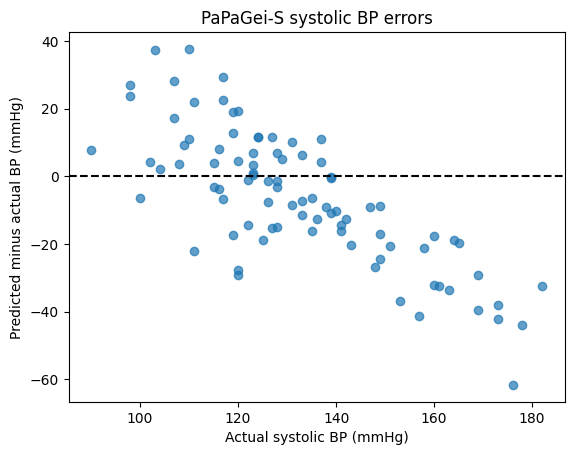

,subject_ID,split,model,target,actual_bp,predicted_bp,absolute_error,signed_error
61,197,test,papagei_s,sysbp,176.0,114.350555,61.649445,-61.649445
3,21,val,papagei_s,sysbp,178.0,133.917923,44.082077,-44.082077
14,51,val,papagei_s,sysbp,173.0,130.709671,42.290329,-42.290329
62,198,val,papagei_s,sysbp,157.0,115.806839,41.193161,-41.193161
29,111,val,papagei_s,sysbp,169.0,129.547119,39.452881,-39.452881


In [40]:
import matplotlib.pyplot as plt

#all 88 systolic predictions for PaPaGei-S are selected
systolic_s = final_predictions.loc[
    final_predictions["model"].eq("papagei_s")
    & final_predictions["target"].eq("sysbp")
].copy()

#negative errors show underestimation
systolic_s["signed_error"] = systolic_s["predicted_bp"] - systolic_s["actual_bp"]

plt.scatter(systolic_s["actual_bp"], systolic_s["signed_error"], alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Actual systolic BP (mmHg)")
plt.ylabel("Predicted minus actual BP (mmHg)")
plt.title("PaPaGei-S systolic BP errors")
plt.show()

#the five largest errors are shown instead of the first five rows
display(systolic_s.nlargest(5, "absolute_error"))

Positive values indicate overestimation and negative values indicate underestimation. Lower readings tend to be overestimated and higher readings underestimated, with predictions staying closer to the middle. This can produce large individual errors, such as predicting about 134 mmHg for an actual reading of 178 mmHg. The graph shows the error pattern, but does not establish its cause.

In [41]:
#the saved predictions are loaded without fitting the models again
final_predictions = pd.read_csv(
    experiment_dir / "final_bp_predictions.csv"
)

#one prediction per participant, model and target is checked
assert not final_predictions.duplicated(
    ["subject_ID", "model", "target"]
).any()
assert final_predictions["split"].isin(["val", "test"]).all()

split_rows = []

for (model_name, target), predictions in final_predictions.groupby(
    ["model", "target"]
):
    assert predictions.loc[
        predictions["split"].eq("val"), "subject_ID"
    ].nunique() == 44
    assert predictions.loc[
        predictions["split"].eq("test"), "subject_ID"
    ].nunique() == 44

    for evaluation in ["val", "test", "val_plus_test"]:
        #the required participants are selected from the existing predictions
        if evaluation == "val_plus_test":
            selected = predictions
        else:
            selected = predictions.loc[
                predictions["split"].eq(evaluation)
            ]

        #the absolute errors are averaged for this evaluation group
        errors = (
            selected["predicted_bp"] - selected["actual_bp"]
        ).abs()

        split_rows.append({
            "model": model_name,
            "target": target,
            "evaluation": evaluation,
            "n_evaluation": len(selected),
            "mae": errors.mean()
        })

#the separate and combined scores are saved for the report
split_results = pd.DataFrame(split_rows)

split_results.to_csv(
    experiment_dir / "final_bp_evaluation_split_comparison.csv",
    index=False
)

#the three evaluation scores are displayed side by side
display(
    split_results.pivot(
        index=["model", "target"],
        columns="evaluation",
        values="mae"
    )[["val", "test", "val_plus_test"]].round(3)
)

evaluation           val    test  val_plus_test
model     target                               
papagei_p diasbp   9.646   8.853          9.250
          sysbp   15.115  15.159         15.137
papagei_s diasbp   9.023   9.062          9.043
          sysbp   16.778  15.917         16.347

##### Checking validation and test errors separately

The saved BP predictions are loaded and checked for duplicate entries, with 44 validation and 44 test participants confirmed for each model and BP target. MAE is then calculated for validation, test and both groups combined. No models are retrained and no settings are changed. The results are saved and displayed side by side in a table.

Validation and test MAEs differ by less than 0.9 mmHg for all four model–target combinations. PaPaGei-P performs better on systolic BP and PaPaGei-S on diastolic BP in both groups. The combined scores therefore do not hide a large difference in average error between the groups, although this does not prove that their data distributions are identical.
 

##### Hypertension classification

Next, hypertension classification is tested using PaPaGei-S and PaPaGei-P. The same 219 participants, split and saved embeddings from the BP regression experiment are used.

Following the released code, “Normal” is labelled as 0 and all other hypertension categories as 1. The label counts are checked first. A logistic regression classifier is then fitted to each model’s embeddings, with settings selected through cross-validation within the training set.

Validation and test participants are combined for evaluation, as in the released code. AUROC is compared with the paper’s results to check how well the embeddings distinguish the two groups.

In [46]:
#the original split files and embedding paths are loaded for the 205-person run
#separate variable names are used so the 219-person experiment is preserved

from pathlib import Path
import pandas as pd

original_data_dir = Path(download_dir)
original_features_dir = original_data_dir / "features"

original_splits = {}

for split_name, expected_count in [
    ("train", 123), ("val", 41), ("test", 41)
]:
    split_data = pd.read_csv(
        original_data_dir / "Data File" / f"{split_name}.csv",
        dtype={"subject_ID": str}
    )

    #participant IDs are formatted to match the original embedding keys
    split_data["subject_ID"] = (
        split_data["subject_ID"].str.zfill(4)
    )

    assert len(split_data) == expected_count
    assert split_data["subject_ID"].is_unique
    assert split_data["Hypertension"].notna().all()

    original_splits[split_name] = split_data

#the supplied participant sets are checked for overlap
train_ids_205 = set(original_splits["train"]["subject_ID"])
val_ids_205 = set(original_splits["val"]["subject_ID"])
test_ids_205 = set(original_splits["test"]["subject_ID"])

assert train_ids_205.isdisjoint(val_ids_205)
assert train_ids_205.isdisjoint(test_ids_205)
assert val_ids_205.isdisjoint(test_ids_205)

#the original participant embeddings are checked for both models
for model_name in ["papagei_s", "papagei_p"]:
    for split_name in original_splits:
        embedding_path = (
            original_features_dir
            / model_name
            / f"dict_{split_name}_patient.p"
        )
        assert embedding_path.is_file(), f"Missing: {embedding_path}"

#the original label counts are displayed before classification
original_label_counts = pd.DataFrame({
    split_name: split_data["Hypertension"].value_counts()
    for split_name, split_data in original_splits.items()
}).fillna(0).astype(int)

display(original_label_counts)
print("Original split and embedding files are available.")

,train,val,test
Normal,46,14,16
Prehypertension,46,16,17
Stage 1 hypertension,22,7,3
Stage 2 hypertension,9,4,5


Original split and embedding files are available.


In [47]:
#the original embeddings are used to fit logistic regression for each model
#scaling is fitted before cross-validation, following the released code
#settings are selected by accuracy using the 123 training participants
#performance is evaluated on the 82 validation and test participants combined
#the results, predictions and fitted models are saved separately from the cleaned run

import numpy as np
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

original_classification_dir = Path("results") / "classification_205_released"
original_classification_dir.mkdir(parents=True, exist_ok=True)

label_mapping = {
    "Normal": 0,
    "Prehypertension": 1,
    "Stage 1 hypertension": 1,
    "Stage 2 hypertension": 1
}

def load_original_classification_data(model_name, split_name):
    embeddings = joblib.load(
        original_features_dir
        / model_name
        / f"dict_{split_name}_patient.p"
    )

    #the dictionary order is preserved as in the released data-loading function
    participant_ids = [str(int(key)).zfill(4) for key in embeddings]
    split_labels = original_splits[split_name].set_index("subject_ID")

    assert len(participant_ids) == len(set(participant_ids))
    assert set(participant_ids) == set(split_labels.index)

    arrays = []
    for value in embeddings.values():
        if hasattr(value, "detach"):
            value = value.detach().cpu().numpy()
        arrays.append(np.asarray(value).reshape(1, -1))

    X = np.vstack(arrays)
    y = split_labels.loc[
        participant_ids, "Hypertension"
    ].map(label_mapping)

    assert y.notna().all()
    assert np.isfinite(X).all()

    return X, y.to_numpy(dtype=int), participant_ids


original_classification_rows = []
original_prediction_tables = []

for model_name in ["papagei_s", "papagei_p"]:
    X_train_205, y_train_205, _ = load_original_classification_data(
        model_name, "train"
    )
    X_val_205, y_val_205, val_ids_205 = load_original_classification_data(
        model_name, "val"
    )
    X_test_205, y_test_205, test_ids_205 = load_original_classification_data(
        model_name, "test"
    )

    #test followed by validation matches the released concatenation order
    X_eval_205 = np.concatenate([X_test_205, X_val_205])
    y_eval_205 = np.concatenate([y_test_205, y_val_205])

    #the scaler is fitted on training only, before the internal CV split
    scaler_205 = StandardScaler()
    X_train_scaled = scaler_205.fit_transform(X_train_205)
    X_eval_scaled = scaler_205.transform(X_eval_205)

    #the valid candidates from the released parameter grid are tested
    search_205 = GridSearchCV(
        LogisticRegression(),
        param_grid={
            "penalty": ["l2"],
            "C": [0.01, 0.1, 1, 10, 100],
            "solver": ["lbfgs"],
            "max_iter": [100, 200]
        },
        cv=4,
        scoring="accuracy",
        n_jobs=-1,
        error_score="raise"
    )
    search_205.fit(X_train_scaled, y_train_205)

    probabilities = search_205.predict_proba(X_eval_scaled)[:, 1]
    predicted_labels = search_205.predict(X_eval_scaled)

    original_classification_rows.append({
        "model": model_name,
        "procedure": "released_205_valid_grid",
        "n_train": len(y_train_205),
        "n_evaluation": len(y_eval_205),
        "auroc": roc_auc_score(y_eval_205, probabilities),
        "accuracy": accuracy_score(y_eval_205, predicted_labels),
        "f1": f1_score(y_eval_205, predicted_labels, zero_division=0),
        **search_205.best_params_
    })

    #individual predictions are saved for confidence intervals and later checks
    original_prediction_tables.append(pd.DataFrame({
        "subject_ID": test_ids_205 + val_ids_205,
        "split": ["test"] * len(test_ids_205) + ["val"] * len(val_ids_205),
        "model": model_name,
        "actual_label": y_eval_205,
        "predicted_label": predicted_labels,
        "probability_non_normal": probabilities
    }))

    joblib.dump(
        {"scaler": scaler_205, "classifier": search_205.best_estimator_},
        original_classification_dir / f"{model_name}_classifier.joblib"
    )
    pd.DataFrame(search_205.cv_results_).to_csv(
        original_classification_dir / f"{model_name}_cv_results.csv",
        index=False
    )

original_classification_results = pd.DataFrame(original_classification_rows)
original_classification_predictions = pd.concat(
    original_prediction_tables, ignore_index=True
)

original_classification_results.to_csv(
    original_classification_dir / "classification_results.csv", index=False
)
original_classification_predictions.to_csv(
    original_classification_dir / "classification_predictions.csv", index=False
)

display(original_classification_results)

,model,procedure,n_train,n_evaluation,auroc,accuracy,f1,C,max_iter,penalty,solver
0,papagei_s,released_205_valid_grid,123,82,0.758333,0.731707,0.807018,0.01,100,l2,lbfgs
1,papagei_p,released_205_valid_grid,123,82,0.638462,0.658537,0.735849,0.10,100,l2,lbfgs


In [42]:
#the hypertension labels are matched to the existing participant split
assert labels["subject_ID"].is_unique

classification_data = (
    new_split[["subject_ID", "split", "group"]]
    .merge(
        labels[["subject_ID", "Hypertension"]],
        on="subject_ID",
        how="left",
        validate="one_to_one"
    )
    .sort_values("subject_ID")
    .reset_index(drop=True)
)

#all 219 participants are checked for missing labels
assert len(classification_data) == 219
assert classification_data["Hypertension"].notna().all()

#the original categories are counted before being converted to binary labels
display(pd.crosstab(
    classification_data["Hypertension"],
    classification_data["split"],
    margins=True
))

split,test,train,val,All
Hypertension,,,,
Normal,12,55,13,80
Prehypertension,15,49,21,85
Stage 1 hypertension,9,20,5,34
Stage 2 hypertension,8,7,5,20
All,44,131,44,219


In [43]:
#the categories are converted using the released code's binary definition
#the four categories are converted to normal (0) or non-normal (1)
#the existing split is used to separate training from evaluation participants
#shared-recording groups are checked to prevent overlap between the two sets
#the labels and split are saved, and the number of participants in each class is shown
label_mapping = {
    "Normal": 0,
    "Prehypertension": 1,
    "Stage 1 hypertension": 1,
    "Stage 2 hypertension": 1
}

classification_data["label"] = (
    classification_data["Hypertension"].map(label_mapping)
)
assert classification_data["label"].notna().all()
classification_data["label"] = classification_data["label"].astype(int)

#training participants are kept separate from the combined evaluation group
classification_train = classification_data.loc[
    classification_data["split"].eq("train")
].copy()

classification_eval = classification_data.loc[
    classification_data["split"].isin(["val", "test"])
].copy()

#shared-recording groups are checked for overlap
assert set(classification_train["group"]).isdisjoint(
    classification_eval["group"]
)
assert len(classification_train) == 131
assert len(classification_eval) == 88

#the labels and split assignments are saved for reproducibility
classification_data.to_csv(
    experiment_dir / "hypertension_labels_and_split.csv",
    index=False
)

#the binary class counts are displayed for both groups
display(pd.DataFrame({
    "training": classification_train["label"].value_counts(),
    "evaluation": classification_eval["label"].value_counts()
}).rename(index={0: "normal", 1: "non-normal"}))

,training,evaluation
non-normal,76,63
normal,55,25


In [ ]:
#logistic regression is fitted to the saved embeddings from each PaPaGei model
#settings are selected by four-fold cross-validation within the training set
#scaling is fitted inside each fold and participants sharing a recording are kept together
#the best settings are selected by accuracy, following the released code
#the fitted classifiers are evaluated on the combined validation and test participants
#AUROC, accuracy and F1 are calculated, and predictions, fitted pipelines and tuning results are saved

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

#the labels and groups are taken from the existing classification tables
y_train_cls = classification_train["label"].to_numpy()
y_eval_cls = classification_eval["label"].to_numpy()
groups_cls = classification_train["group"].to_numpy()

#class proportions are approximately preserved while shared groups stay together
classification_cv = StratifiedGroupKFold(n_splits=4, shuffle=False)
classification_folds = list(classification_cv.split(
    classification_train, y_train_cls, groups_cls
))

for fit_idx, check_idx in classification_folds:
    assert set(groups_cls[fit_idx]).isdisjoint(groups_cls[check_idx])
    assert len(np.unique(y_train_cls[fit_idx])) == 2
    assert len(np.unique(y_train_cls[check_idx])) == 2

#only compatible settings from the released grid are included
classification_grid = {
    "classifier__penalty": ["l2"],
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__max_iter": [100, 200]
}

classification_rows = []
classification_prediction_tables = []

for model_name in ["papagei_s", "papagei_p"]:
    #the saved embeddings are matched to the participant order
    embeddings = joblib.load(
        experiment_dir / f"{model_name}_participant_embeddings.p"
    )
    X_train_cls = np.stack([
        embeddings[int(pid)]
        for pid in classification_train["subject_ID"]
    ])
    X_eval_cls = np.stack([
        embeddings[int(pid)]
        for pid in classification_eval["subject_ID"]
    ])

    #scaling and tuning are performed using training data only
    search_cls = GridSearchCV(
        Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression())
        ]),
        param_grid=classification_grid,
        cv=classification_folds,
        scoring="accuracy",
        n_jobs=-1,
        error_score="raise"
    )
    search_cls.fit(X_train_cls, y_train_cls)

    #probabilities and class predictions are calculated for evaluation participants
    probabilities = search_cls.predict_proba(X_eval_cls)[:, 1]
    predicted_labels = search_cls.predict(X_eval_cls)

    classification_rows.append({
        "model": model_name,
        "n_train": len(y_train_cls),
        "n_evaluation": len(y_eval_cls),
        "auroc": roc_auc_score(y_eval_cls, probabilities),
        "accuracy": accuracy_score(y_eval_cls, predicted_labels),
        "f1": f1_score(y_eval_cls, predicted_labels, zero_division=0),
        "C": search_cls.best_params_["classifier__C"],
        "max_iter": search_cls.best_params_["classifier__max_iter"]
    })

    #individual predictions are kept for later analysis and confidence intervals
    prediction_table = classification_eval[
        ["subject_ID", "split", "group"]
    ].copy()
    prediction_table["model"] = model_name
    prediction_table["actual_label"] = y_eval_cls
    prediction_table["predicted_label"] = predicted_labels
    prediction_table["probability_non_normal"] = probabilities
    classification_prediction_tables.append(prediction_table)

    #the fitted pipeline and tuning results are saved
    joblib.dump(
        search_cls.best_estimator_,
        experiment_dir / f"{model_name}_hypertension_pipeline.joblib"
    )
    pd.DataFrame(search_cls.cv_results_).to_csv(
        experiment_dir / f"{model_name}_hypertension_cv.csv",
        index=False
    )

#the summary and individual predictions are saved separately
classification_results = pd.DataFrame(classification_rows)
classification_predictions = pd.concat(
    classification_prediction_tables, ignore_index=True
)

classification_results.to_csv(
    experiment_dir / "hypertension_results.csv", index=False
)
classification_predictions.to_csv(
    experiment_dir / "hypertension_predictions.csv", index=False
)

display(classification_results)

,model,n_train,n_evaluation,auroc,accuracy,f1,C,max_iter
0,papagei_s,131,88,0.641270,0.647727,0.752000,0.10,100
1,papagei_p,131,88,0.707937,0.659091,0.741379,0.01,100


In [45]:
#the saved classification results are compared with the paper's hypertension AUROC
#95% confidence intervals are estimated using 500 bootstrap samples with seed 42
#the same resampled participants are used for both models
#the reproduced AUROC minus the published AUROC is saved for the report

classification_results = pd.read_csv(
    experiment_dir / "hypertension_results.csv"
)
classification_predictions = pd.read_csv(
    experiment_dir / "hypertension_predictions.csv"
)

#predictions are arranged in the same participant order for both models
prediction_groups = {
    model: rows.sort_values("subject_ID").reset_index(drop=True)
    for model, rows in classification_predictions.groupby("model")
}

reference = prediction_groups["papagei_s"]

for rows in prediction_groups.values():
    assert rows["subject_ID"].equals(reference["subject_ID"])
    assert rows["actual_label"].equals(reference["actual_label"])

#resamples containing both classes are retained so AUROC can be calculated
rng = np.random.default_rng(42)
y_reference = reference["actual_label"].to_numpy()
bootstrap_indices = []

while len(bootstrap_indices) < 500:
    indices = rng.integers(
        0, len(y_reference), size=len(y_reference)
    )
    if np.unique(y_reference[indices]).size == 2:
        bootstrap_indices.append(indices)

ci_rows = []

for model_name, rows in prediction_groups.items():
    actual = rows["actual_label"].to_numpy()
    probabilities = rows["probability_non_normal"].to_numpy()

    bootstrap_auc = [
        roc_auc_score(actual[idx], probabilities[idx])
        for idx in bootstrap_indices
    ]
    lower, upper = np.percentile(bootstrap_auc, [2.5, 97.5])

    ci_rows.append({
        "model": model_name,
        "ci_lower": lower,
        "ci_upper": upper
    })

#the published values are taken from Table 3
paper_classification = pd.DataFrame({
    "model": ["papagei_s", "papagei_p"],
    "paper_auroc": [0.77, 0.74],
    "paper_ci_lower": [0.68, 0.55],
    "paper_ci_upper": [0.87, 0.90]
})

classification_comparison = (
    classification_results
    .merge(pd.DataFrame(ci_rows), on="model", validate="one_to_one")
    .merge(paper_classification, on="model", validate="one_to_one")
)

#negative differences indicate lower AUROC than the paper
classification_comparison["auroc_difference"] = (
    classification_comparison["auroc"]
    - classification_comparison["paper_auroc"]
)
classification_comparison["bootstrap_seed"] = 42
classification_comparison["bootstrap_samples"] = 500

classification_comparison.to_csv(
    experiment_dir / "hypertension_paper_comparison.csv",
    index=False
)

display(classification_comparison[[
    "model", "auroc", "ci_lower", "ci_upper",
    "paper_auroc", "paper_ci_lower", "paper_ci_upper",
    "auroc_difference"
]].round(3))

,model,auroc,ci_lower,ci_upper,paper_auroc,paper_ci_lower,paper_ci_upper,auroc_difference
0,papagei_s,0.641,0.479,0.775,0.77,0.68,0.87,-0.129
1,papagei_p,0.708,0.556,0.833,0.74,0.55,0.90,-0.032


In [48]:
#confidence intervals are calculated for the 205-person classification results
#500 bootstrap samples are drawn using seed 42, with the same samples used for both models
#the paper, released-procedure run and adapted run are compared and saved

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

results_205 = pd.read_csv(
    original_classification_dir / "classification_results.csv"
)
predictions_205 = pd.read_csv(
    original_classification_dir / "classification_predictions.csv"
)
comparison_219 = pd.read_csv(
    experiment_dir / "hypertension_paper_comparison.csv"
)

#participant order and actual labels are checked across the two models
prediction_groups_205 = {
    model: rows.sort_values("subject_ID").reset_index(drop=True)
    for model, rows in predictions_205.groupby("model")
}

reference_205 = prediction_groups_205["papagei_s"]
assert len(reference_205) == 82

for rows in prediction_groups_205.values():
    assert rows["subject_ID"].is_unique
    assert rows["subject_ID"].equals(reference_205["subject_ID"])
    assert rows["actual_label"].equals(reference_205["actual_label"])

#resamples containing both classes are retained so AUROC can be calculated
rng = np.random.default_rng(42)
y_reference_205 = reference_205["actual_label"].to_numpy()
bootstrap_indices_205 = []

while len(bootstrap_indices_205) < 500:
    indices = rng.integers(
        0, len(y_reference_205), size=len(y_reference_205)
    )
    if np.unique(y_reference_205[indices]).size == 2:
        bootstrap_indices_205.append(indices)

ci_rows_205 = []

for model_name, rows in prediction_groups_205.items():
    actual = rows["actual_label"].to_numpy()
    probabilities = rows["probability_non_normal"].to_numpy()

    bootstrap_auc = [
        roc_auc_score(actual[idx], probabilities[idx])
        for idx in bootstrap_indices_205
    ]
    lower, upper = np.percentile(bootstrap_auc, [2.5, 97.5])

    ci_rows_205.append({
        "model": model_name,
        "ci_lower": lower,
        "ci_upper": upper
    })

#the confidence intervals are saved alongside the original performance metrics
results_205_ci = results_205.merge(
    pd.DataFrame(ci_rows_205),
    on="model",
    validate="one_to_one"
)
results_205_ci["bootstrap_seed"] = 42
results_205_ci["bootstrap_samples"] = 500

results_205_ci.to_csv(
    original_classification_dir / "classification_results_with_ci.csv",
    index=False
)

#the published values are reused from the saved paper comparison
comparison_all = comparison_219[[
    "model", "paper_auroc", "paper_ci_lower", "paper_ci_upper",
    "auroc", "ci_lower", "ci_upper"
]].rename(columns={
    "auroc": "auroc_219",
    "ci_lower": "ci_lower_219",
    "ci_upper": "ci_upper_219"
})

comparison_all = comparison_all.merge(
    results_205_ci[[
        "model", "auroc", "ci_lower", "ci_upper"
    ]].rename(columns={
        "auroc": "auroc_205",
        "ci_lower": "ci_lower_205",
        "ci_upper": "ci_upper_205"
    }),
    on="model",
    validate="one_to_one"
)

#negative differences indicate lower AUROC than the published result
comparison_all["205_minus_paper"] = (
    comparison_all["auroc_205"] - comparison_all["paper_auroc"]
)
comparison_all["219_minus_paper"] = (
    comparison_all["auroc_219"] - comparison_all["paper_auroc"]
)

comparison_all.to_csv(
    original_classification_dir / "classification_three_way_comparison.csv",
    index=False
)

display(comparison_all[[
    "model",
    "paper_auroc", "paper_ci_lower", "paper_ci_upper",
    "auroc_205", "ci_lower_205", "ci_upper_205",
    "auroc_219", "ci_lower_219", "ci_upper_219",
    "205_minus_paper", "219_minus_paper"
]].round(3))

,model,paper_auroc,paper_ci_lower,paper_ci_upper,auroc_205,ci_lower_205,ci_upper_205,auroc_219,ci_lower_219,ci_upper_219,205_minus_paper,219_minus_paper
0,papagei_s,0.77,0.68,0.87,0.758,0.647,0.861,0.641,0.479,0.775,-0.012,-0.129
1,papagei_p,0.74,0.55,0.90,0.638,0.505,0.766,0.708,0.556,0.833,-0.102,-0.032


##### Classification reproduction: original and adapted setups

Two classification setups were compared. First, the released procedure was followed as closely as possible using the supplied 205-person split and original embeddings. Logistic regression was tuned using four-fold cross-validation within the 123 training participants, with scaling performed before CV and accuracy used to select settings. Evaluation was carried out on the 82 validation and test participants combined. The incompatible l1/lbfgs candidates were omitted.

PaPaGei-S reached AUROC 0.758, close to the paper’s 0.770. PaPaGei-P reached 0.638, below the reported 0.740. The paper’s ranking was reproduced, with S performing better than P, although both published scores were not matched.

In the adapted 219-person setup, S reached 0.641 and P reached 0.708, reversing the ranking. This setup used a new split, duplicate handling, grouped cross-validation and scaling inside CV. Since several things changed together, the difference cannot be attributed to cleaning alone. Adding participants also changed who was used for training and evaluation, so a larger dataset did not necessarily produce a higher score.

The 205-person run is the closer reproduction of the released procedure. The 219-person run provides an additional evaluation under documented adaptations. Neither confirms the exact setup used to obtain the paper’s table.

Confidence intervals were estimated using 500 bootstrap resamples with seed 42. These describe uncertainty from resampling the evaluation participants while keeping the fitted model fixed. They do not measure variation from retraining on different splits or confidence in individual predictions.

The main finding is that S came close to its published AUROC under the released procedure, while P came closer under the adapted setup. The cause of the remaining differences has not been isolated.